# Exploratory Data Analysis Lab - Telco Customer Churn
Dataset: https://raw.githubusercontent.com/salemprakash/EDA/main/Data/telco%20customer%20churn.csv

In [1]:
%matplotlib inline

### Setup - Imports & Dataset URL

In [2]:
#Setup - Imports & Dataset URL
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from pandas.plotting import parallel_coordinates
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/telco%20customer%20churn.csv"
REG_NO = "23BDS0280"
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 110)


def load_raw():
    return pd.read_csv(URL, lineterminator="\r", na_values=["?", " ", ""])


def load_clean():
    d = load_raw()
    for c in d.select_dtypes(include="number").columns:
        d[c] = d[c].fillna(d[c].median())
    for c in d.select_dtypes(exclude="number").columns:
        d[c] = d[c].fillna(d[c].mode()[0])
    return d.drop_duplicates().reset_index(drop=True)


def r_scale(x):
    return (x - x.mean()) / x.std(ddof=1)

## PDF 2 - Data Import, Transform and Basic Statistical Analysis

### Import Dataset - PDF #2 - Question #1

In [3]:
#Import Dataset - PDF #2 - Question #1
df = load_raw()
df_raw = df.copy()

### First 10 Records - PDF #2 - Question #2

In [4]:
#First 10 Records - PDF #2 - Question #2
print(df.head(10))

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines  \
0  7590-VHVEG  Female            0.0     Yes         No     1.0           No  No phone service   
1  5575-GNVDE    Male            0.0      No         No    34.0          Yes                No   
2  3668-QPYBK    Male            0.0      No         No     2.0          Yes                No   
3  7795-CFOCW    Male            0.0      No         No    45.0           No  No phone service   
4  9237-HQITU  Female            0.0      No         No     2.0          Yes                No   
5  9305-CDSKC  Female            0.0      No         No     8.0          Yes               Yes   
6  1452-KIOVK    Male            0.0      No        Yes    22.0          Yes               Yes   
7  6713-OKOMC  Female            0.0      No         No    10.0           No  No phone service   
8  7892-POOKP  Female            0.0     Yes         No    28.0          Yes               Yes   
9  6388-TABGU    Mal

### Last 10 Records - PDF #2 - Question #3

In [5]:
#Last 10 Records - PDF #2 - Question #3
print(df.tail(10))

      customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines  \
7033  9767-FFLEM    Male            0.0      No         No    38.0          Yes                No   
7034  0639-TSIQW  Female            0.0      No         No    67.0          Yes               Yes   
7035  8456-QDAVC    Male            0.0      No         No    19.0          Yes                No   
7036  7750-EYXWZ  Female            0.0      No         No    12.0           No  No phone service   
7037  2569-WGERO  Female            0.0      No         No    72.0          Yes                No   
7038  6840-RESVB    Male            0.0     Yes        Yes    24.0          Yes               Yes   
7039  2234-XADUH  Female            0.0     Yes        Yes    72.0          Yes               Yes   
7040  4801-JZAZL  Female            0.0     Yes        Yes    11.0           No  No phone service   
7041  8361-LTMKD    Male            1.0     Yes         No     4.0          Yes            

### Rows and Columns - PDF #2 - Question #4

In [6]:
#Rows and Columns - PDF #2 - Question #4
print("Rows:", df.shape[0], "Columns:", df.shape[1])

Rows: 7043 Columns: 21


### Variable Names - PDF #2 - Question #5

In [7]:
#Variable Names - PDF #2 - Question #5
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### Data Type / Structure - PDF #2 - Question #6

In [8]:
#Data Type / Structure - PDF #2 - Question #6
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7035 non-null   float64
 3   Partner           7038 non-null   str    
 4   Dependents        7041 non-null   str    
 5   tenure            7041 non-null   float64
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7042 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7042 non-null   str    
 17  Paymen

### Summary Statistics - PDF #2 - Question #7

In [9]:
#Summary Statistics - PDF #2 - Question #7
print(df.describe(include="all"))

        customerID gender  SeniorCitizen Partner Dependents       tenure PhoneService MultipleLines  \
count         7043   7043    7035.000000    7038       7041  7041.000000         7043          7043   
unique        7043      2            NaN       2          2          NaN            2             3   
top     7590-VHVEG   Male            NaN      No         No          NaN          Yes            No   
freq             1   3555            NaN    3640       4931          NaN         6361          3390   
mean           NaN    NaN       0.162331     NaN        NaN    32.373242          NaN           NaN   
std            NaN    NaN       0.368781     NaN        NaN    24.562077          NaN           NaN   
min            NaN    NaN       0.000000     NaN        NaN     0.000000          NaN           NaN   
25%            NaN    NaN       0.000000     NaN        NaN     9.000000          NaN           NaN   
50%            NaN    NaN       0.000000     NaN        NaN    29.000000 

### Missing Values per Column - PDF #2 - Question #8

In [10]:
#Missing Values per Column - PDF #2 - Question #8
print(df.isna().sum())

customerID           0
gender               0
SeniorCitizen        8
Partner              5
Dependents           2
tenure               2
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          1
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     1
PaymentMethod        0
MonthlyCharges       3
TotalCharges        11
Churn                3
dtype: int64


### Total Missing Values - PDF #2 - Question #9

In [11]:
#Total Missing Values - PDF #2 - Question #9
print("Total missing:", df.isna().sum().sum())

Total missing: 36


### Missing Values per Column - PDF #2 - Question #10

In [12]:
#Missing Values per Column - PDF #2 - Question #10
print(df.isna().sum()[df.isna().sum() > 0])

SeniorCitizen        8
Partner              5
Dependents           2
tenure               2
TechSupport          1
PaperlessBilling     1
MonthlyCharges       3
TotalCharges        11
Churn                3
dtype: int64


### Rows with at least one Missing Value - PDF #2 - Question #11

In [13]:
#Rows with at least one Missing Value - PDF #2 - Question #11
na_rows = df[df.isna().any(axis=1)]
print("Rows with NA:", len(na_rows))
print(na_rows.head(10))

Rows with NA: 34
     customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines  \
16   8191-XWSZG  Female            NaN      No         No    52.0          Yes                No   
369  3520-FJGCV    Male            NaN     Yes        Yes    72.0          Yes               Yes   
370  6563-VRERX    Male            NaN     Yes        Yes    33.0          Yes                No   
371  0259-GBZSH    Male            NaN      No         No     2.0          Yes               Yes   
372  6122-EFVKN    Male            NaN      No        Yes    24.0           No  No phone service   
373  2805-EDJPQ  Female            NaN     Yes        Yes    56.0          Yes               Yes   
374  6862-CQUMB    Male            NaN      No         No    37.0          Yes                No   
375  7156-MXBJE  Female            NaN      No         No    43.0          Yes               Yes   
472  1304-BCCFO    Male            0.0     NaN         No     9.0          Yes     

### Remove Rows with Missing Values - PDF #2 - Question #12

In [14]:
#Remove Rows with Missing Values - PDF #2 - Question #12
df_dropped = df.dropna()
print(df_dropped.shape)
print(df_dropped.head(10))

(7009, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines  \
0  7590-VHVEG  Female            0.0     Yes         No     1.0           No  No phone service   
1  5575-GNVDE    Male            0.0      No         No    34.0          Yes                No   
2  3668-QPYBK    Male            0.0      No         No     2.0          Yes                No   
3  7795-CFOCW    Male            0.0      No         No    45.0           No  No phone service   
4  9237-HQITU  Female            0.0      No         No     2.0          Yes                No   
5  9305-CDSKC  Female            0.0      No         No     8.0          Yes               Yes   
6  1452-KIOVK    Male            0.0      No        Yes    22.0          Yes               Yes   
7  6713-OKOMC  Female            0.0      No         No    10.0           No  No phone service   
8  7892-POOKP  Female            0.0     Yes         No    28.0          Yes               Yes   
9  6388-T

### Mean Imputation (MonthlyCharges) - PDF #2 - Question #13

In [15]:
#Mean Imputation (MonthlyCharges) - PDF #2 - Question #13
df["MonthlyCharges"] = df["MonthlyCharges"].fillna(df["MonthlyCharges"].mean())
print(df["MonthlyCharges"].isna().sum())

0


### Median Imputation (TotalCharges) - PDF #2 - Question #14

In [16]:
#Median Imputation (TotalCharges) - PDF #2 - Question #14
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
print(df["TotalCharges"].isna().sum())

0


### Mode Imputation (Partner) - PDF #2 - Question #15

In [17]:
#Mode Imputation (Partner) - PDF #2 - Question #15
df["Partner"] = df["Partner"].fillna(df["Partner"].mode()[0])
print(df["Partner"].isna().sum())

0


### Forward Fill - PDF #2 - Question #16

In [18]:
#Forward Fill - PDF #2 - Question #16
df_ffill = df_raw.ffill()
print(df_ffill.isna().sum().sum())

0


### Backward Fill - PDF #2 - Question #17

In [19]:
#Backward Fill - PDF #2 - Question #17
df_bfill = df_raw.bfill()
print(df_bfill.isna().sum().sum())

0


### Constant Fill (0 / "Unknown") - PDF #2 - Question #18

In [20]:
#Constant Fill (0 / "Unknown") - PDF #2 - Question #18
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns
df[num_cols] = df[num_cols].fillna(0)
df[cat_cols] = df[cat_cols].fillna("Unknown")
print(df.isna().sum().sum())

0


### Remove Duplicates - PDF #2 - Question #19

In [21]:
#Remove Duplicates - PDF #2 - Question #19
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print(df.shape)

Duplicates: 0


(7043, 21)


### Convert to Factors (category) - PDF #2 - Question #20

In [22]:
#Convert to Factors (category) - PDF #2 - Question #20
factor_cols = [c for c in cat_cols if c != "customerID"] + ["SeniorCitizen"]
df[factor_cols] = df[factor_cols].astype("category")
print(df.dtypes)

customerID               str
gender              category
SeniorCitizen       category
Partner             category
Dependents          category
tenure               float64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges         float64
Churn               category
dtype: object


### Rename Columns - PDF #2 - Question #21

In [23]:
#Rename Columns - PDF #2 - Question #21
df = df.rename(columns={"tenure": "Tenure", "gender": "Gender"})
print(df.columns.tolist())

['customerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### Derived Column - PDF #2 - Question #22

In [24]:
#Derived Column - PDF #2 - Question #22
df["AvgChargePerMonth"] = np.where(df["Tenure"] > 0, df["TotalCharges"] / df["Tenure"], df["MonthlyCharges"])
print(df[["Tenure", "TotalCharges", "AvgChargePerMonth"]].head(10))

   Tenure  TotalCharges  AvgChargePerMonth
0     1.0         29.85          29.850000
1    34.0       1889.50          55.573529
2     2.0        108.15          54.075000
3    45.0       1840.75          40.905556
4     2.0        151.65          75.825000
5     8.0        820.50         102.562500
6    22.0       1949.40          88.609091
7    10.0        301.90          30.190000
8    28.0       3046.05         108.787500
9    62.0       3487.95          56.257258


### Summary Statistics - PDF #2 - Question #23

In [25]:
#Summary Statistics - PDF #2 - Question #23
print(df.describe(include="all"))

        customerID Gender  SeniorCitizen Partner Dependents       Tenure PhoneService MultipleLines  \
count         7043   7043         7043.0    7043       7043  7043.000000         7043          7043   
unique        7043      2            2.0       2          3          NaN            2             3   
top     7590-VHVEG   Male            0.0      No         No          NaN          Yes            No   
freq             1   3555         5901.0    3645       4931          NaN         6361          3390   
mean           NaN    NaN            NaN     NaN        NaN    32.364049          NaN           NaN   
std            NaN    NaN            NaN     NaN        NaN    24.564646          NaN           NaN   
min            NaN    NaN            NaN     NaN        NaN     0.000000          NaN           NaN   
25%            NaN    NaN            NaN     NaN        NaN     9.000000          NaN           NaN   
50%            NaN    NaN            NaN     NaN        NaN    29.000000 

### Minimum and Maximum - PDF #2 - Question #24

In [26]:
#Minimum and Maximum - PDF #2 - Question #24
print(df.select_dtypes(include="number").agg(["min", "max"]))

     Tenure  MonthlyCharges  TotalCharges  AvgChargePerMonth
min     0.0           18.25          18.8             13.775
max    72.0          118.75        8684.8            121.400


### Range - PDF #2 - Question #25

In [27]:
#Range - PDF #2 - Question #25
print("Range of MonthlyCharges:", df["MonthlyCharges"].max() - df["MonthlyCharges"].min())

Range of MonthlyCharges: 100.5


### Variance - PDF #2 - Question #26

In [28]:
#Variance - PDF #2 - Question #26
print("Variance of MonthlyCharges:", df["MonthlyCharges"].var())

Variance of MonthlyCharges: 904.865031933198


### Standard Deviation - PDF #2 - Question #27

In [29]:
#Standard Deviation - PDF #2 - Question #27
print("SD of MonthlyCharges:", df["MonthlyCharges"].std())

SD of MonthlyCharges: 30.080974584165286


### Interquartile Range (IQR) - PDF #2 - Question #28

In [30]:
#Interquartile Range (IQR) - PDF #2 - Question #28
print("IQR of MonthlyCharges:", df["MonthlyCharges"].quantile(0.75) - df["MonthlyCharges"].quantile(0.25))

IQR of MonthlyCharges: 54.324999999999996


## PDF 3 - Data Cleaning and Univariate Analysis

### Import Dataset - PDF #3 - Question #1

In [31]:
#Import Dataset - PDF #3 - Question #1
df = load_raw()

### First and Last 6 Records - PDF #3 - Question #2

In [32]:
#First and Last 6 Records - PDF #3 - Question #2
print(df.head(6))
print(df.tail(6))

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines  \
0  7590-VHVEG  Female            0.0     Yes         No     1.0           No  No phone service   
1  5575-GNVDE    Male            0.0      No         No    34.0          Yes                No   
2  3668-QPYBK    Male            0.0      No         No     2.0          Yes                No   
3  7795-CFOCW    Male            0.0      No         No    45.0           No  No phone service   
4  9237-HQITU  Female            0.0      No         No     2.0          Yes                No   
5  9305-CDSKC  Female            0.0      No         No     8.0          Yes               Yes   

  InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies  \
0             DSL             No          Yes               No          No          No              No   
1             DSL            Yes           No              Yes          No          No              N

### Total Missing Values - PDF #3 - Question #3

In [33]:
#Total Missing Values - PDF #3 - Question #3
print("Total missing:", df.isna().sum().sum())

Total missing: 36


### Records with at least one Missing Value - PDF #3 - Question #4

In [34]:
#Records with at least one Missing Value - PDF #3 - Question #4
print(df[df.isna().any(axis=1)])

      customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines  \
16    8191-XWSZG  Female            NaN      No         No    52.0          Yes                No   
369   3520-FJGCV    Male            NaN     Yes        Yes    72.0          Yes               Yes   
370   6563-VRERX    Male            NaN     Yes        Yes    33.0          Yes                No   
371   0259-GBZSH    Male            NaN      No         No     2.0          Yes               Yes   
372   6122-EFVKN    Male            NaN      No        Yes    24.0           No  No phone service   
373   2805-EDJPQ  Female            NaN     Yes        Yes    56.0          Yes               Yes   
374   6862-CQUMB    Male            NaN      No         No    37.0          Yes                No   
375   7156-MXBJE  Female            NaN      No         No    43.0          Yes               Yes   
472   1304-BCCFO    Male            0.0     NaN         No     9.0          Yes            

### Remove Columns with >70% Missing - PDF #3 - Question #5

In [35]:
#Remove Columns with >70% Missing - PDF #3 - Question #5
miss_pct = df.isna().mean() * 100
print(miss_pct.round(3))
df = df.loc[:, miss_pct <= 70]
print(df.shape)

customerID          0.000
gender              0.000
SeniorCitizen       0.114
Partner             0.071
Dependents          0.028
tenure              0.028
PhoneService        0.000
MultipleLines       0.000
InternetService     0.000
OnlineSecurity      0.000
OnlineBackup        0.000
DeviceProtection    0.000
TechSupport         0.014
StreamingTV         0.000
StreamingMovies     0.000
Contract            0.000
PaperlessBilling    0.014
PaymentMethod       0.000
MonthlyCharges      0.043
TotalCharges        0.156
Churn               0.043
dtype: float64
(7043, 21)


### Mean Imputation (Numerical) - PDF #3 - Question #6

In [36]:
#Mean Imputation (Numerical) - PDF #3 - Question #6
num_cols = df.select_dtypes(include="number").columns
df_mean = df.copy()
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())
print(df_mean[num_cols].isna().sum())

SeniorCitizen     0
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


### Median Imputation (Numerical) - PDF #3 - Question #7

In [37]:
#Median Imputation (Numerical) - PDF #3 - Question #7
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
print(df[num_cols].isna().sum())

SeniorCitizen     0
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


### Mode Imputation (Categorical) - PDF #3 - Question #8

In [38]:
#Mode Imputation (Categorical) - PDF #3 - Question #8
cat_cols = df.select_dtypes(exclude="number").columns
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])
print(df.isna().sum().sum())

0


### Identify Duplicate Rows - PDF #3 - Question #9

In [39]:
#Identify Duplicate Rows - PDF #3 - Question #9
print("Duplicate rows:", df.duplicated().sum())
print(df[df.duplicated()])

Duplicate rows: 0
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []


### Remove Duplicate Rows - PDF #3 - Question #10

In [40]:
#Remove Duplicate Rows - PDF #3 - Question #10
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(7043, 21)


### Identify Incorrect Data Types - PDF #3 - Question #11

In [41]:
#Identify Incorrect Data Types - PDF #3 - Question #11
raw_str = pd.read_csv(URL, lineterminator="\r", dtype=str)
for c in raw_str.columns:
    if pd.to_numeric(raw_str[c], errors="coerce").notna().mean() > 0.95 and raw_str[c].str.contains(r"[?\s]", na=False).any():
        print(f"{c}: stored as text, should be numeric")
for c in num_cols:
    if df[c].nunique() <= 2:
        print(f"{c}: stored as numeric, should be categorical")

tenure: stored as text, should be numeric
TotalCharges: stored as text, should be numeric
SeniorCitizen: stored as numeric, should be categorical


### Convert Character Variables to Factors - PDF #3 - Question #12

In [42]:
#Convert Character Variables to Factors - PDF #3 - Question #12
factor_cols = [c for c in cat_cols if c != "customerID"] + ["SeniorCitizen"]
df[factor_cols] = df[factor_cols].astype("category")
print(df.dtypes)

customerID               str
gender              category
SeniorCitizen       category
Partner             category
Dependents          category
tenure               float64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges         float64
Churn               category
dtype: object


### Lowercase / Uppercase - PDF #3 - Question #13

In [43]:
#Lowercase / Uppercase - PDF #3 - Question #13
df["gender"] = df["gender"].astype(str).str.lower().astype("category")
df["Contract"] = df["Contract"].astype(str).str.upper().astype("category")
df["customerID"] = df["customerID"].str.lower()
print(df[["customerID", "gender", "Contract"]].head())

   customerID  gender        Contract
0  7590-vhveg  female  MONTH-TO-MONTH
1  5575-gnvde    male        ONE YEAR
2  3668-qpybk    male  MONTH-TO-MONTH
3  7795-cfocw    male        ONE YEAR
4  9237-hqitu  female  MONTH-TO-MONTH


### Detect Outliers - Boxplots - PDF #3 - Question #14

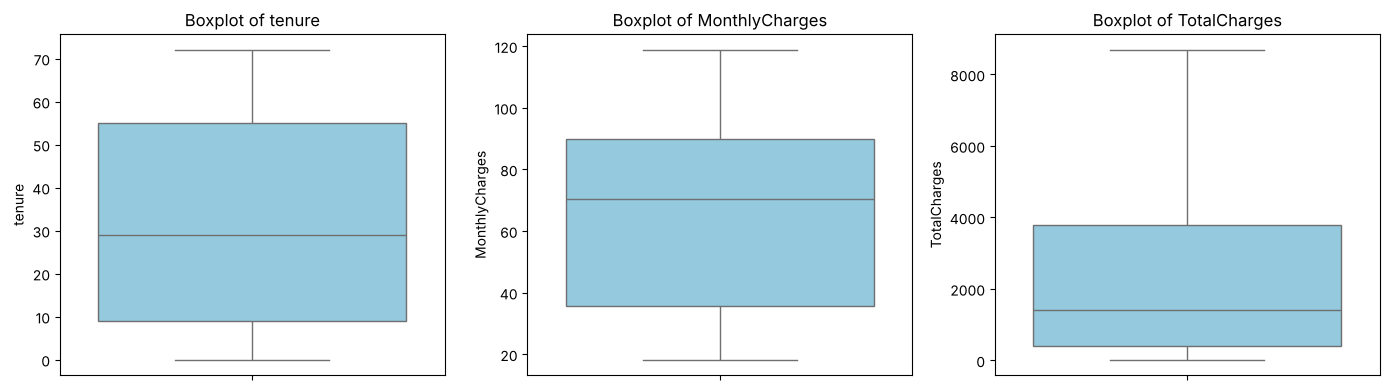

In [44]:
#Detect Outliers - Boxplots - PDF #3 - Question #14
cont_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, cont_cols):
    sns.boxplot(y=df[c], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot of {c}")
plt.tight_layout()
plt.show()

### Identify Outliers - IQR Method - PDF #3 - Question #15

In [45]:
#Identify Outliers - IQR Method - PDF #3 - Question #15
for c in cont_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    print(f"{c}: bounds=({lo:.2f}, {hi:.2f}), outliers={((df[c] < lo) | (df[c] > hi)).sum()}")

tenure: bounds=(-60.00, 124.00), outliers=0
MonthlyCharges: bounds=(-45.96, 171.34), outliers=0
TotalCharges: bounds=(-4674.34, 8863.16), outliers=0


### Remove Extreme Outliers - PDF #3 - Question #16

In [46]:
#Remove Extreme Outliers - PDF #3 - Question #16
mask = pd.Series(True, index=df.index)
for c in cont_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask &= df[c].between(q1 - 3 * iqr, q3 + 3 * iqr)
print("Before:", df.shape)
df = df[mask].reset_index(drop=True)
print("After:", df.shape)

Before: (7043, 21)
After: (7043, 21)


### Histogram + Interpretation - PDF #3 - Question #17

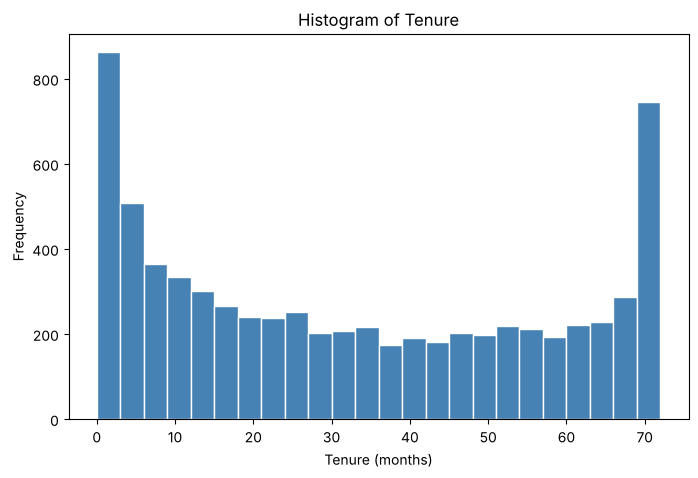

Skewness=0.239 -> approximately symmetric | peaks at very new (<6 mo) and long-term (~72 mo) customers -> bimodal


In [47]:
#Histogram + Interpretation - PDF #3 - Question #17
plt.figure(figsize=(8, 5))
plt.hist(df["tenure"], bins=24, color="steelblue", edgecolor="white")
plt.title("Histogram of Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Frequency")
plt.show()
sk = df["tenure"].skew()
print(f"Skewness={sk:.3f} ->", "right-skewed" if sk > 0.5 else "left-skewed" if sk < -0.5 else "approximately symmetric",
      "| peaks at very new (<6 mo) and long-term (~72 mo) customers -> bimodal")

### Histogram with Density Curve - PDF #3 - Question #18

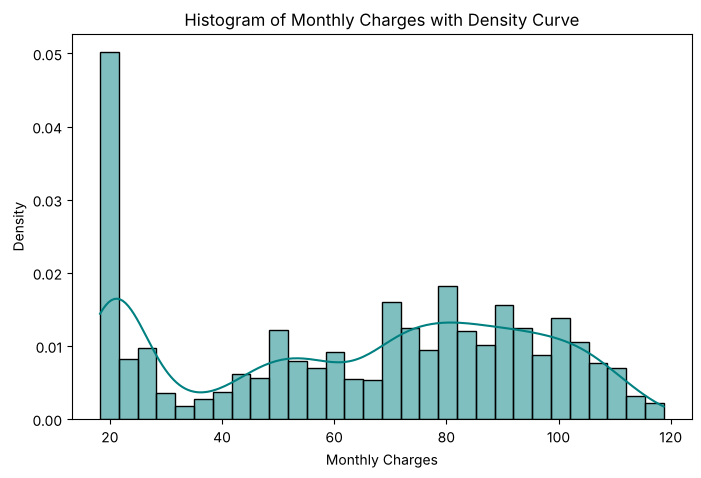

In [48]:
#Histogram with Density Curve - PDF #3 - Question #18
plt.figure(figsize=(8, 5))
sns.histplot(df["MonthlyCharges"], bins=30, kde=True, stat="density", color="teal")
plt.title("Histogram of Monthly Charges with Density Curve")
plt.xlabel("Monthly Charges")
plt.show()

### Violin Plot - PDF #3 - Question #19

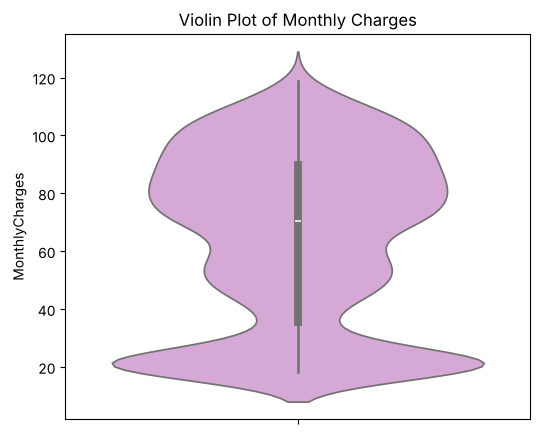

In [49]:
#Violin Plot - PDF #3 - Question #19
plt.figure(figsize=(6, 5))
sns.violinplot(y=df["MonthlyCharges"], color="plum")
plt.title("Violin Plot of Monthly Charges")
plt.show()

### Dot Plot (small sample) - PDF #3 - Question #20

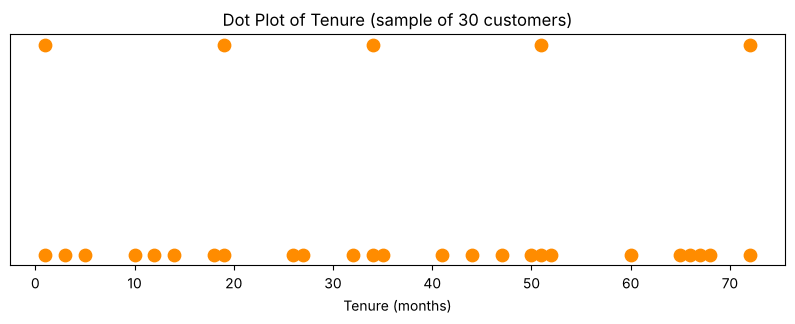

In [50]:
#Dot Plot (small sample) - PDF #3 - Question #20
small = df["tenure"].sample(30, random_state=1).astype(int)
counts = {}
xs, ys = [], []
for v in sorted(small):
    counts[v] = counts.get(v, 0) + 1
    xs.append(v)
    ys.append(counts[v])
plt.figure(figsize=(10, 3))
plt.scatter(xs, ys, s=80, color="darkorange")
plt.yticks([])
plt.title("Dot Plot of Tenure (sample of 30 customers)")
plt.xlabel("Tenure (months)")
plt.show()

### Frequency Table - PDF #3 - Question #21

In [51]:
#Frequency Table - PDF #3 - Question #21
freq = df["PaymentMethod"].value_counts()
print(freq)

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


### Proportion and Percentage - PDF #3 - Question #22

In [52]:
#Proportion and Percentage - PDF #3 - Question #22
print(pd.DataFrame({"Frequency": freq, "Proportion": (freq / freq.sum()).round(4),
                    "Percentage": (freq / freq.sum() * 100).round(2)}))

                           Frequency  Proportion  Percentage
PaymentMethod                                               
Electronic check                2365      0.3358       33.58
Mailed check                    1612      0.2289       22.89
Bank transfer (automatic)       1544      0.2192       21.92
Credit card (automatic)         1522      0.2161       21.61


### Bar Chart - PDF #3 - Question #23

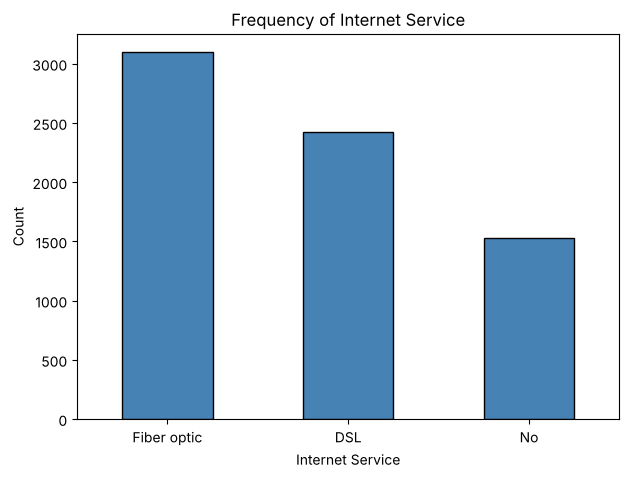

In [53]:
#Bar Chart - PDF #3 - Question #23
plt.figure(figsize=(7, 5))
df["InternetService"].value_counts().plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Frequency of Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

### Horizontal Bar Chart - PDF #3 - Question #24

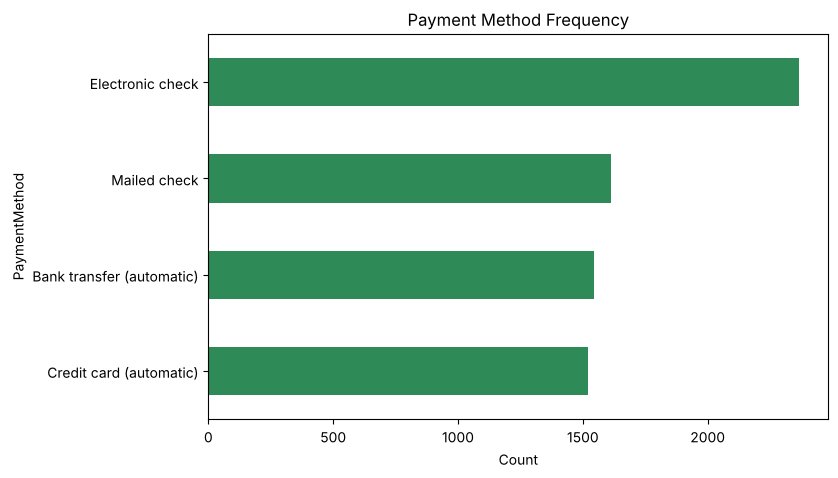

In [54]:
#Horizontal Bar Chart - PDF #3 - Question #24
plt.figure(figsize=(8, 5))
freq.sort_values().plot(kind="barh", color="seagreen")
plt.title("Payment Method Frequency")
plt.xlabel("Count")
plt.show()

### Percentage Bar Chart - PDF #3 - Question #25

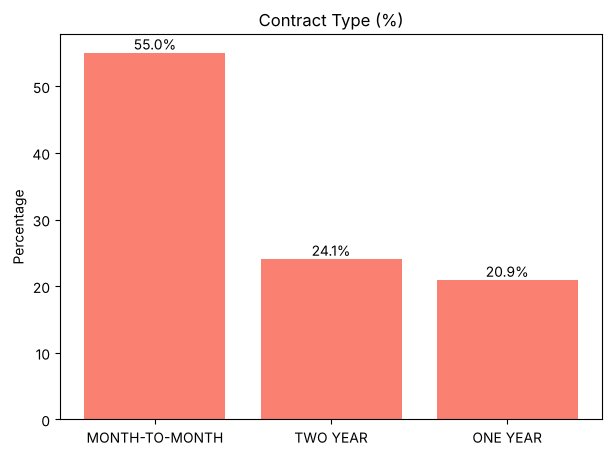

In [55]:
#Percentage Bar Chart - PDF #3 - Question #25
pct = df["Contract"].value_counts(normalize=True) * 100
plt.figure(figsize=(7, 5))
bars = plt.bar(pct.index.astype(str), pct.values, color="salmon")
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Contract Type (%)")
plt.ylabel("Percentage")
plt.show()

### Pie Chart - PDF #3 - Question #26

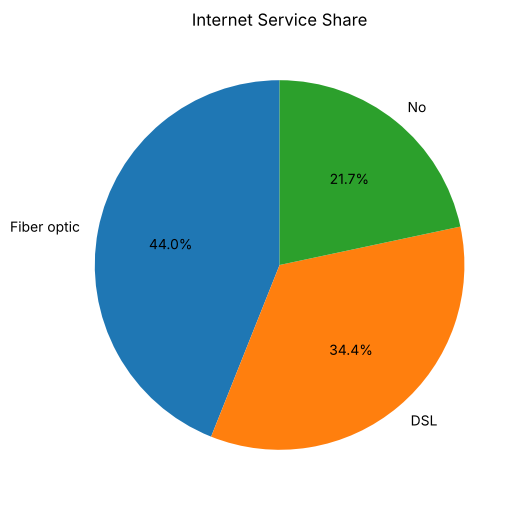

In [56]:
#Pie Chart - PDF #3 - Question #26
plt.figure(figsize=(6, 6))
df["InternetService"].value_counts().plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Internet Service Share")
plt.ylabel("")
plt.show()

### Lollipop Chart - PDF #3 - Question #27

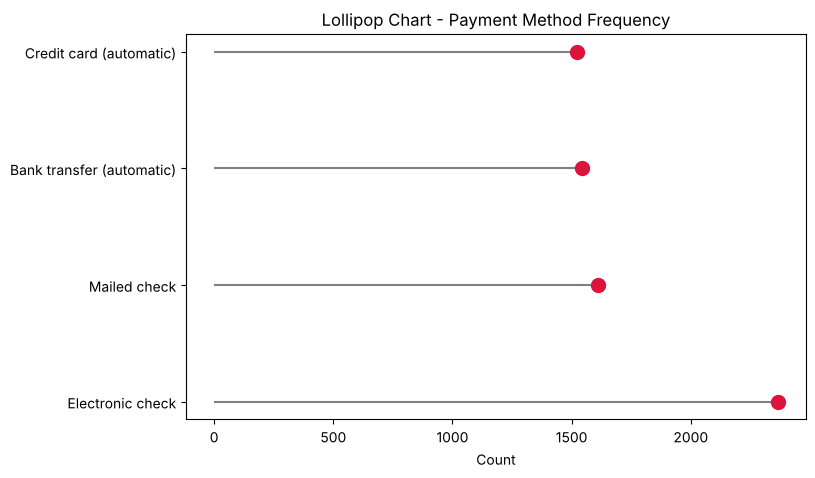

In [57]:
#Lollipop Chart - PDF #3 - Question #27
plt.figure(figsize=(8, 5))
plt.hlines(y=freq.index, xmin=0, xmax=freq.values, color="grey")
plt.plot(freq.values, freq.index, "o", markersize=10, color="crimson")
plt.title("Lollipop Chart - Payment Method Frequency")
plt.xlabel("Count")
plt.show()

### Dot Chart - PDF #3 - Question #28

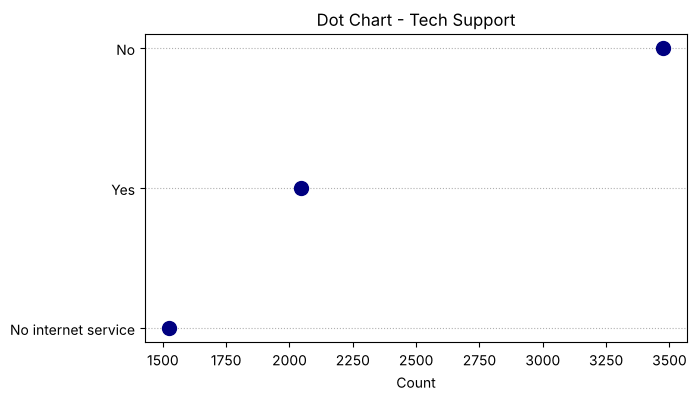

In [58]:
#Dot Chart - PDF #3 - Question #28
tech = df["TechSupport"].value_counts().sort_values()
plt.figure(figsize=(7, 4))
plt.plot(tech.values, tech.index.astype(str), "o", markersize=10, color="navy")
plt.grid(axis="y", linestyle=":")
plt.title("Dot Chart - Tech Support")
plt.xlabel("Count")
plt.show()

### Density Plot - PDF #3 - Question #29

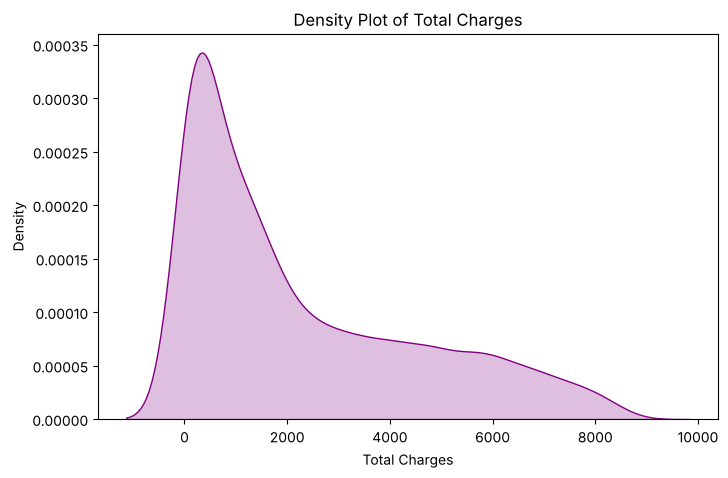

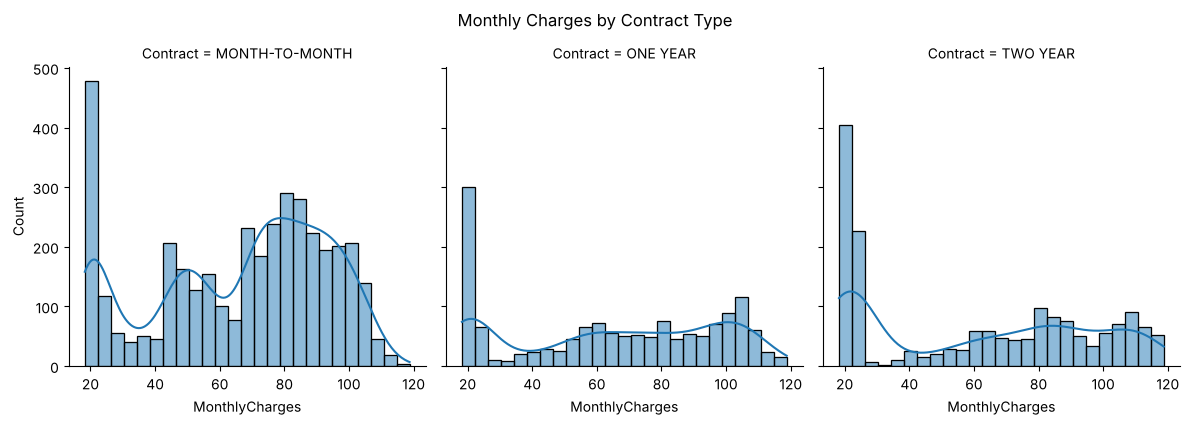

MONTH-TO-MONTH: mean=66.40, median=73.25, sd=26.93, skew=-0.41
ONE YEAR: mean=65.02, median=68.75, sd=31.82, skew=-0.17
TWO YEAR: mean=60.80, median=64.35, sd=34.67, skew=0.08


In [59]:
#Density Plot - PDF #3 - Question #29
plt.figure(figsize=(8, 5))
sns.kdeplot(df["TotalCharges"], fill=True, color="purple")
plt.title("Density Plot of Total Charges")
plt.xlabel("Total Charges")
plt.show()

#facet_wrap Distribution by Group - PDF #3 - Question #30
g = sns.displot(data=df, x="MonthlyCharges", col="Contract", bins=25, kde=True, height=4)
g.figure.suptitle("Monthly Charges by Contract Type", y=1.05)
plt.show()
for grp, sub in df.groupby("Contract", observed=True)["MonthlyCharges"]:
    print(f"{grp}: mean={sub.mean():.2f}, median={sub.median():.2f}, sd={sub.std():.2f}, skew={sub.skew():.2f}")

## PDF 4 - Bivariate Analysis

### Load Dataset - PDF #4 - Question #1

In [60]:
#Load Dataset - PDF #4 - Question #1
df = load_clean()

### Contingency Table + Stacked Bar (Base) - PDF #4 - Question #2

Churn             No   Yes
Contract                  
Month-to-month  2221  1654
One year        1307   166
Two year        1647    48


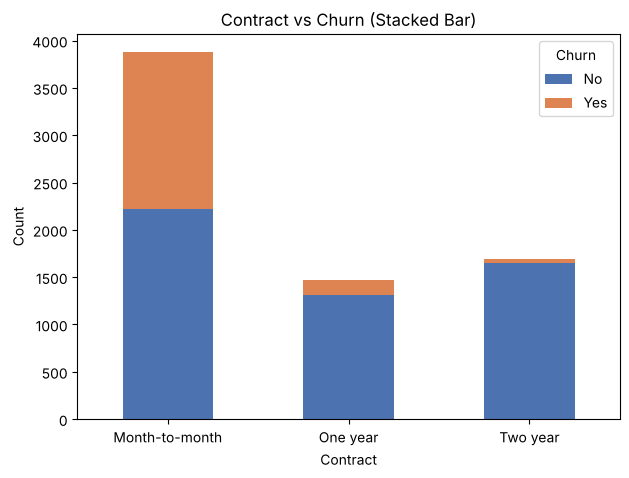

In [61]:
#Contingency Table + Stacked Bar (Base) - PDF #4 - Question #2
ct = pd.crosstab(df["Contract"], df["Churn"])
print(ct)
ct.plot(kind="bar", stacked=True, color=["#4C72B0", "#DD8452"], figsize=(7, 5))
plt.title("Contract vs Churn (Stacked Bar)")
plt.xlabel("Contract")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

### Contingency Table + Stacked Bar (seaborn / ggplot style) - PDF #4 - Question #2

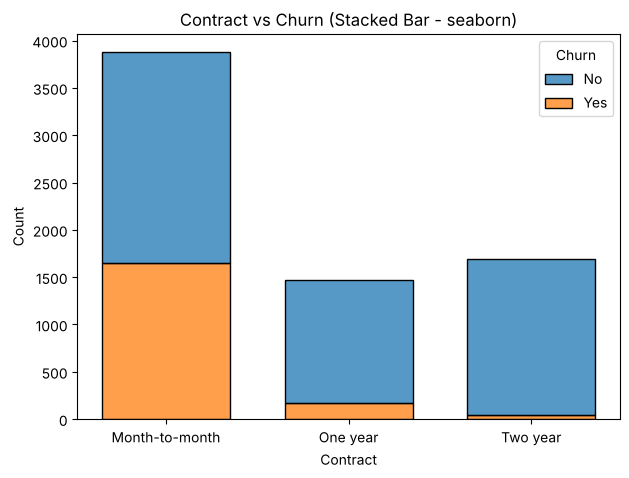

In [62]:
#Contingency Table + Stacked Bar (seaborn / ggplot style) - PDF #4 - Question #2
plt.figure(figsize=(7, 5))
sns.histplot(data=df, x="Contract", hue="Churn", multiple="stack", shrink=0.7, discrete=True)
plt.title("Contract vs Churn (Stacked Bar - seaborn)")
plt.ylabel("Count")
plt.show()

### Grouped Bar Plot - PDF #4 - Question #3

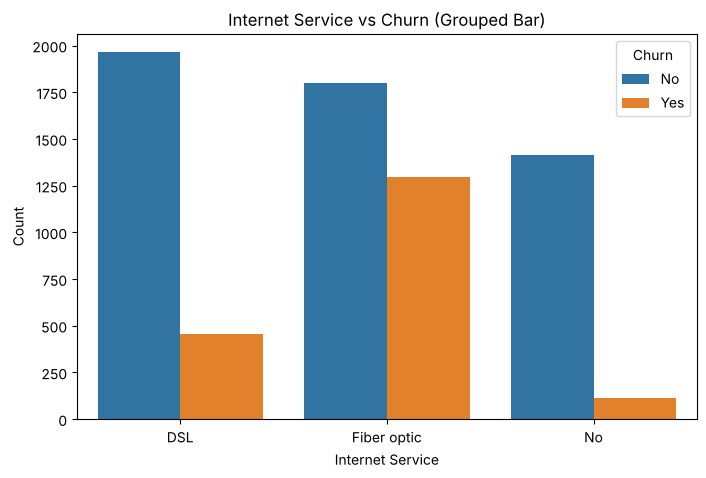

In [63]:
#Grouped Bar Plot - PDF #4 - Question #3
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Internet Service vs Churn (Grouped Bar)")
plt.xlabel("Internet Service")
plt.ylabel("Count")
plt.show()

### Scatter Plot - PDF #4 - Question #4

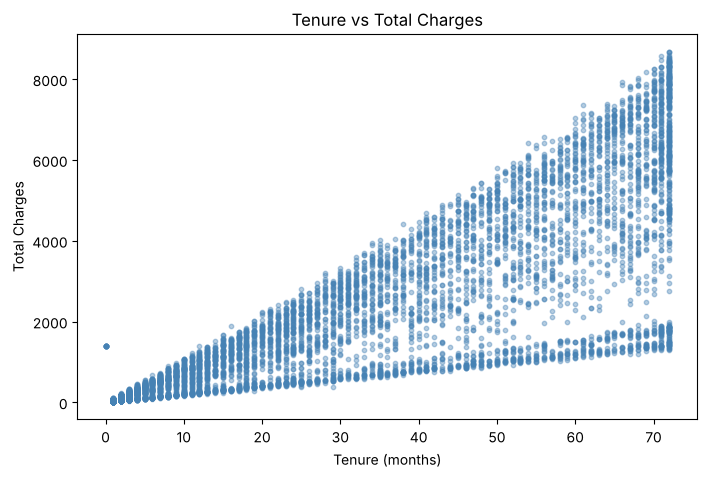

In [64]:
#Scatter Plot - PDF #4 - Question #4
plt.figure(figsize=(8, 5))
plt.scatter(df["tenure"], df["TotalCharges"], alpha=0.4, s=10, color="steelblue")
plt.title("Tenure vs Total Charges")
plt.xlabel("Tenure (months)")
plt.ylabel("Total Charges")
plt.show()

### Line Plot - PDF #4 - Question #5

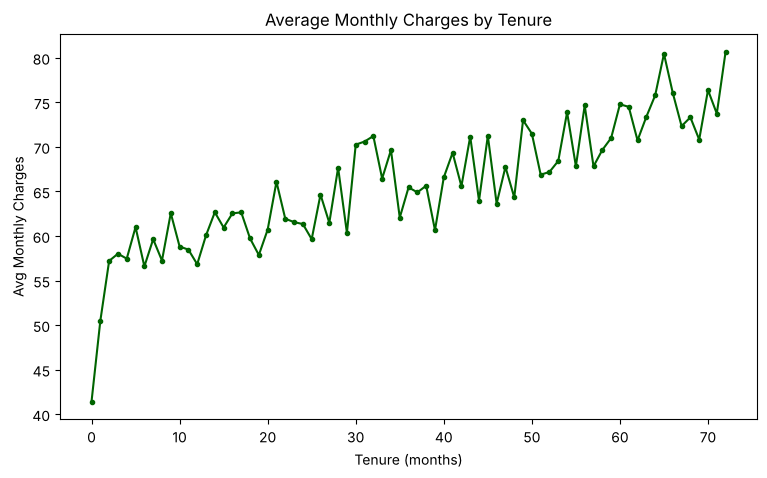

In [65]:
#Line Plot - PDF #4 - Question #5
trend = df.groupby("tenure")["MonthlyCharges"].mean()
plt.figure(figsize=(9, 5))
plt.plot(trend.index, trend.values, marker="o", markersize=3, color="darkgreen")
plt.title("Average Monthly Charges by Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Avg Monthly Charges")
plt.show()

### Heatmap - PDF #4 - Question #6

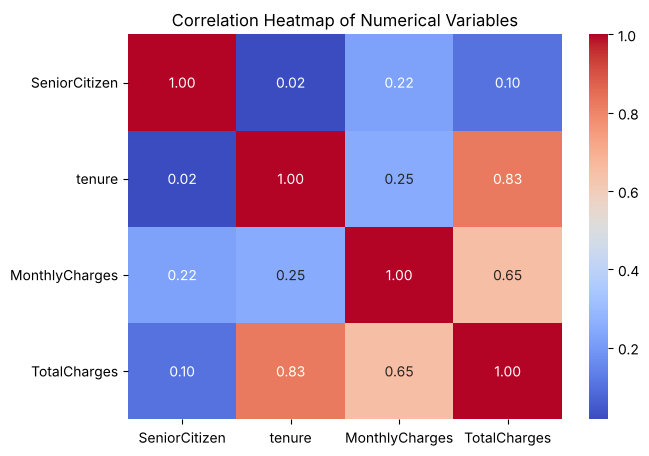

In [66]:
#Heatmap - PDF #4 - Question #6
num = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]]
plt.figure(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

### Bar Chart Comparing Two Variables - PDF #4 - Question #7

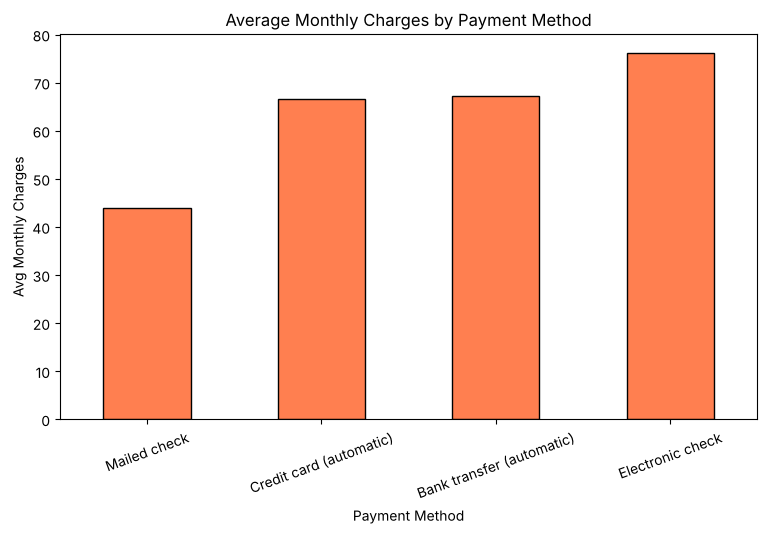

In [67]:
#Bar Chart Comparing Two Variables - PDF #4 - Question #7
avg_pm = df.groupby("PaymentMethod")["MonthlyCharges"].mean().sort_values()
plt.figure(figsize=(9, 5))
avg_pm.plot(kind="bar", color="coral", edgecolor="black")
plt.title("Average Monthly Charges by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Avg Monthly Charges")
plt.xticks(rotation=20)
plt.show()

### Density Plot by Category - PDF #4 - Question #8

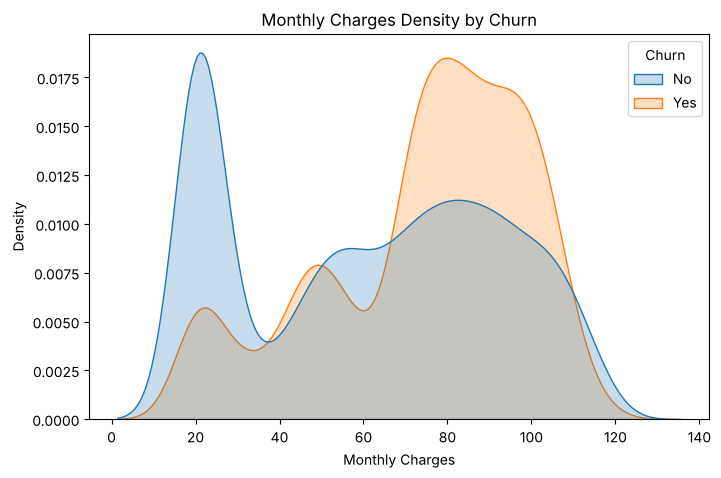

In [68]:
#Density Plot by Category - PDF #4 - Question #8
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True, common_norm=False)
plt.title("Monthly Charges Density by Churn")
plt.xlabel("Monthly Charges")
plt.show()

### Box Plot - PDF #4 - Question #9

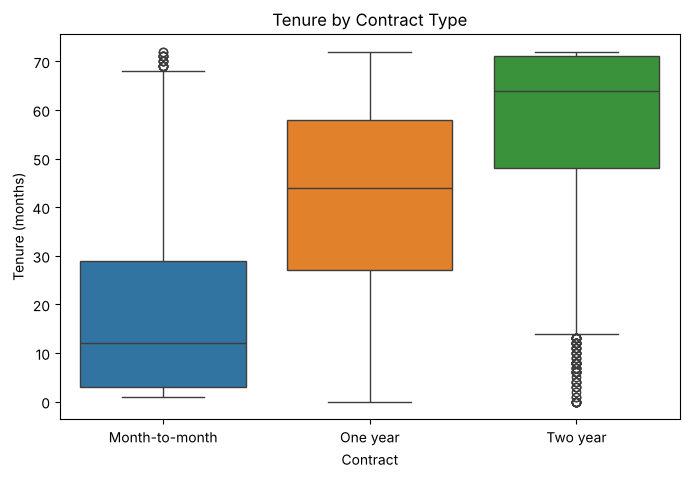

In [69]:
#Box Plot - PDF #4 - Question #9
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Contract", y="tenure", hue="Contract", legend=False)
plt.title("Tenure by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Tenure (months)")
plt.show()

### Violin Plot - PDF #4 - Question #10

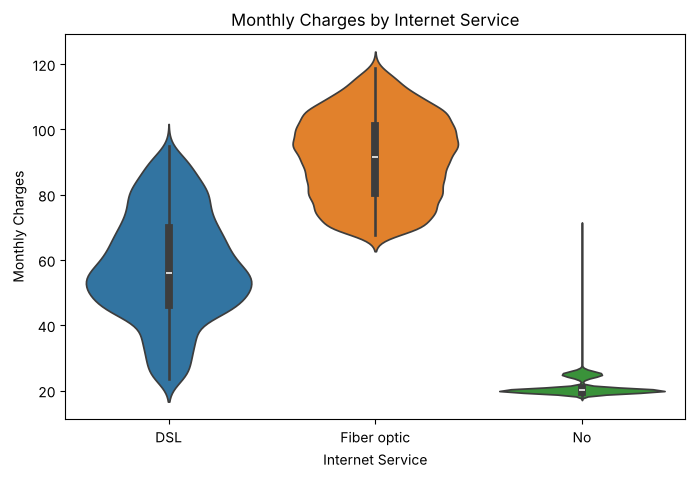

In [70]:
#Violin Plot - PDF #4 - Question #10
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="InternetService", y="MonthlyCharges", hue="InternetService", legend=False)
plt.title("Monthly Charges by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Monthly Charges")
plt.show()

### Violin + Box Plot Combined - PDF #4 - Question #11

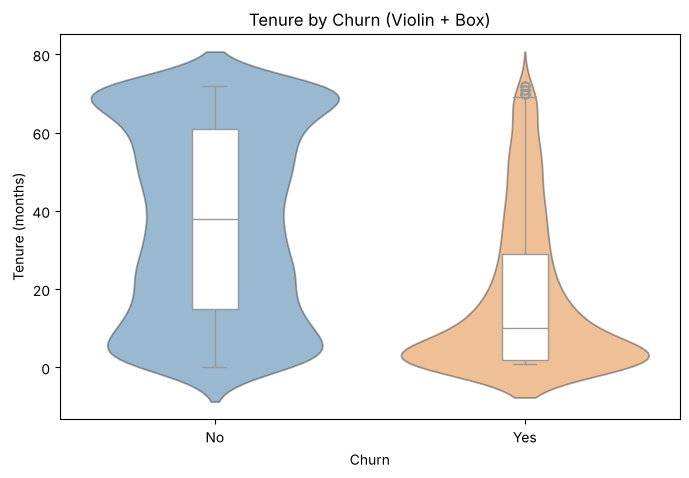

In [71]:
#Violin + Box Plot Combined - PDF #4 - Question #11
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="Churn", y="tenure", hue="Churn", inner=None, legend=False, alpha=0.5)
sns.boxplot(data=df, x="Churn", y="tenure", width=0.15, color="white")
plt.title("Tenure by Churn (Violin + Box)")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

### Correlation Matrix + Correlogram - PDF #4 - Question #12

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.016547        0.220200      0.102652
tenure               0.016547  1.000000        0.247916      0.825433
MonthlyCharges       0.220200  0.247916        1.000000      0.650558
TotalCharges         0.102652  0.825433        0.650558      1.000000


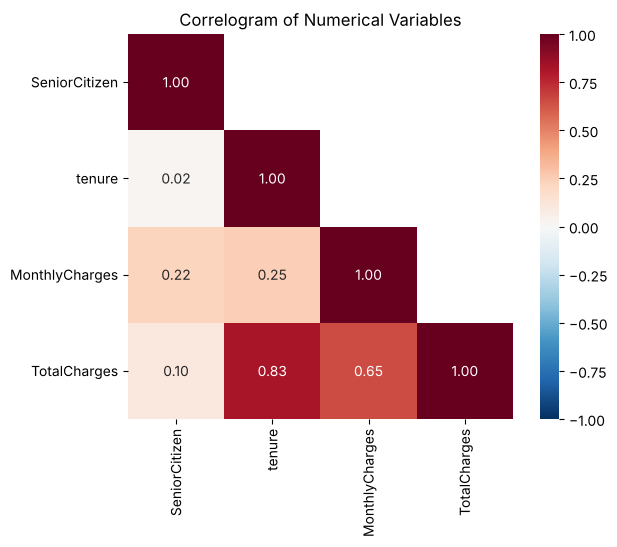

In [72]:
#Correlation Matrix + Correlogram - PDF #4 - Question #12
corr = num.corr()
print(corr)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, mask=mask, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, square=True, fmt=".2f")
plt.title("Correlogram of Numerical Variables")
plt.show()

### Titles, Labels, Legends - PDF #4 - Question #13

In [73]:
#Titles, Labels, Legends - PDF #4 - Question #13
# applied to every plot above

## PDF 5 - Multivariate Analysis

### Load Dataset + Identify Variable Types - PDF #5 - Question #1

In [74]:
#Load Dataset + Identify Variable Types - PDF #5 - Question #1
df = load_clean()
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


### Scatter - 3 Variables (color) - PDF #5 - Question #2

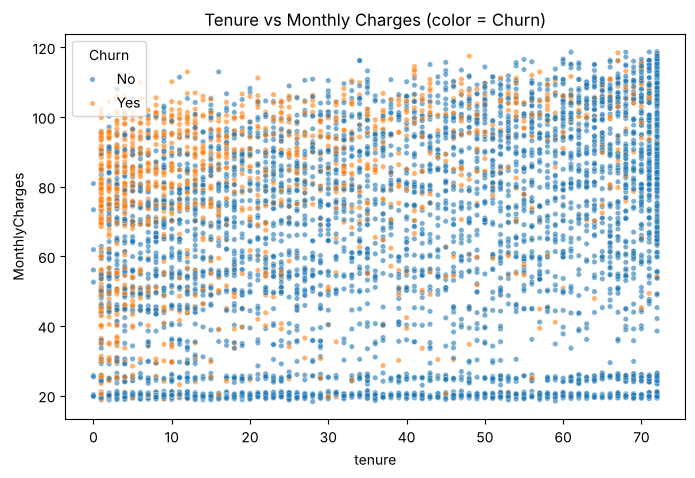

In [75]:
#Scatter - 3 Variables (color) - PDF #5 - Question #2
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.6, s=15)
plt.title("Tenure vs Monthly Charges (color = Churn)")
plt.show()

### Scatter - 4 Variables (color + shape) - PDF #5 - Question #3

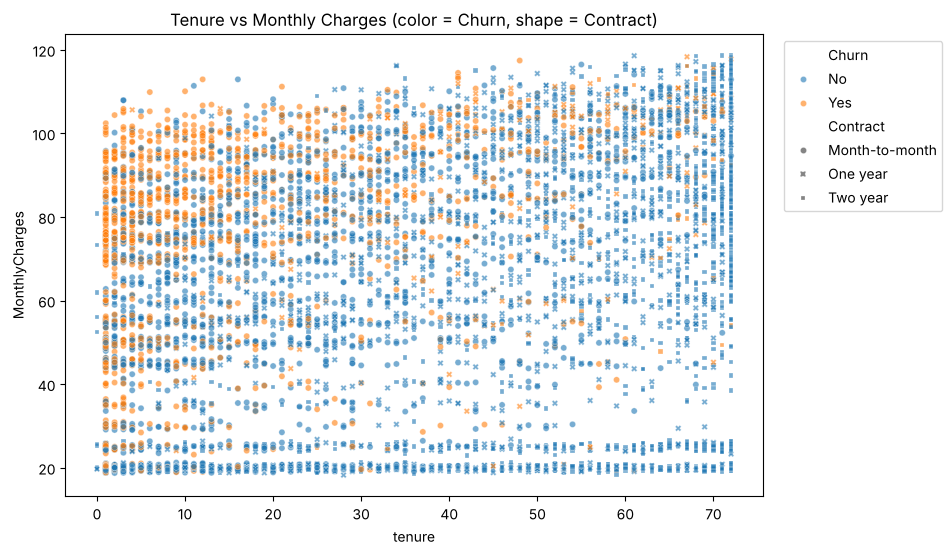

In [76]:
#Scatter - 4 Variables (color + shape) - PDF #5 - Question #3
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="Churn", style="Contract", alpha=0.6, s=20)
plt.title("Tenure vs Monthly Charges (color = Churn, shape = Contract)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### Scatter - 4 Variables (color + size) - PDF #5 - Question #4

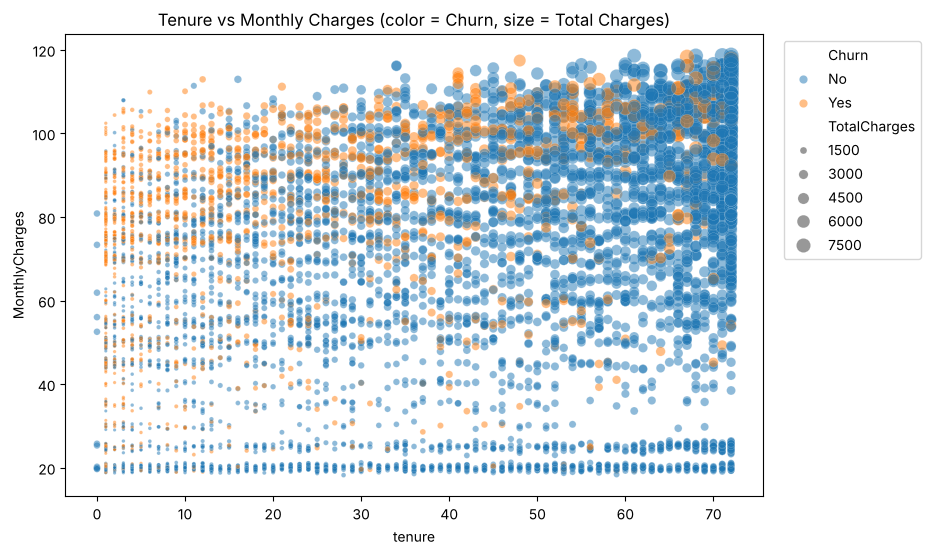

In [77]:
#Scatter - 4 Variables (color + size) - PDF #5 - Question #4
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="Churn", size="TotalCharges", sizes=(5, 120), alpha=0.5)
plt.title("Tenure vs Monthly Charges (color = Churn, size = Total Charges)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### Bubble Plot - PDF #5 - Question #5

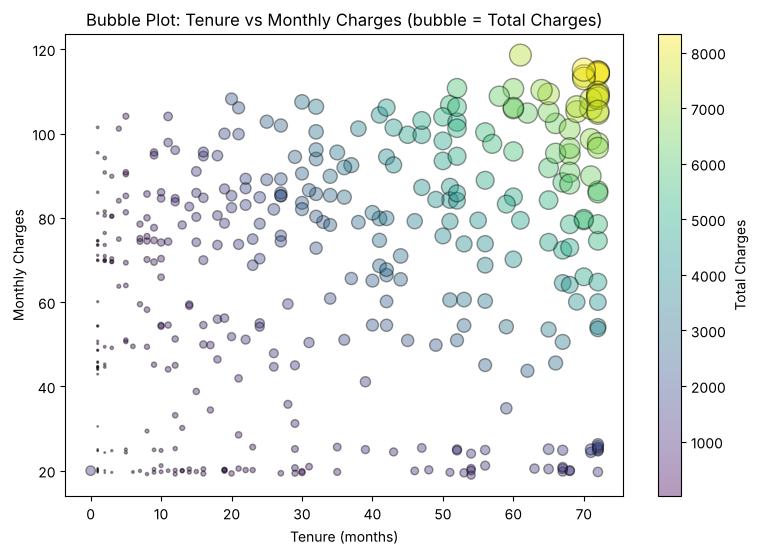

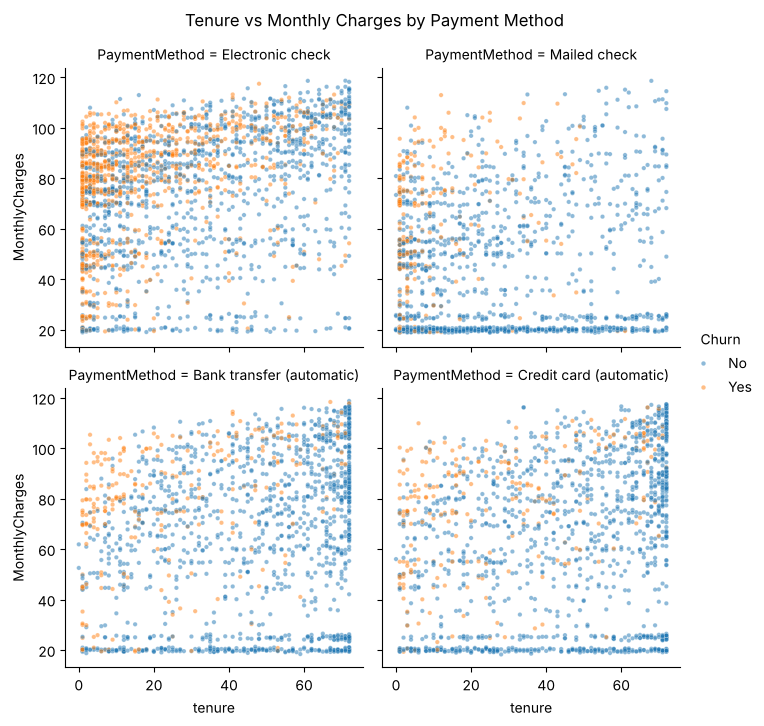

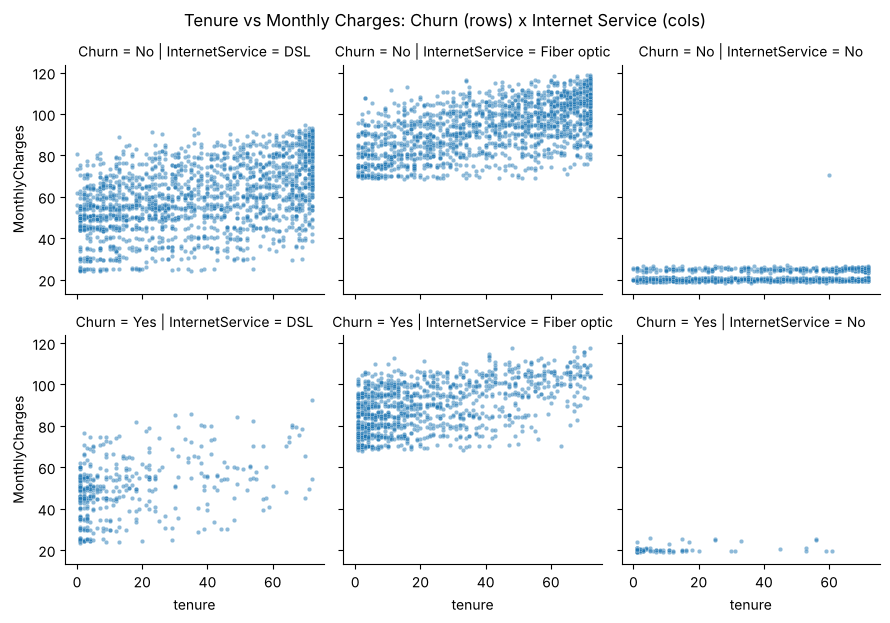

In [78]:
#Bubble Plot - PDF #5 - Question #5
samp = df.sample(400, random_state=1)
plt.figure(figsize=(9, 6))
plt.scatter(samp["tenure"], samp["MonthlyCharges"], s=samp["TotalCharges"] / 30, alpha=0.4,
            c=samp["TotalCharges"], cmap="viridis", edgecolors="black")
plt.colorbar(label="Total Charges")
plt.title("Bubble Plot: Tenure vs Monthly Charges (bubble = Total Charges)")
plt.xlabel("Tenure (months)")
plt.ylabel("Monthly Charges")
plt.show()

#facet_wrap Subplots - PDF #5 - Question #6
g = sns.relplot(data=df, x="tenure", y="MonthlyCharges", col="PaymentMethod", col_wrap=2, hue="Churn", s=10, alpha=0.5, height=3.5)
g.figure.suptitle("Tenure vs Monthly Charges by Payment Method", y=1.03)
plt.show()

#facet_grid Subplots - PDF #5 - Question #7
g = sns.relplot(data=df, x="tenure", y="MonthlyCharges", row="Churn", col="InternetService", s=10, alpha=0.5, height=3)
g.figure.suptitle("Tenure vs Monthly Charges: Churn (rows) x Internet Service (cols)", y=1.03)
plt.show()

### Pairs Plot - PDF #5 - Question #8

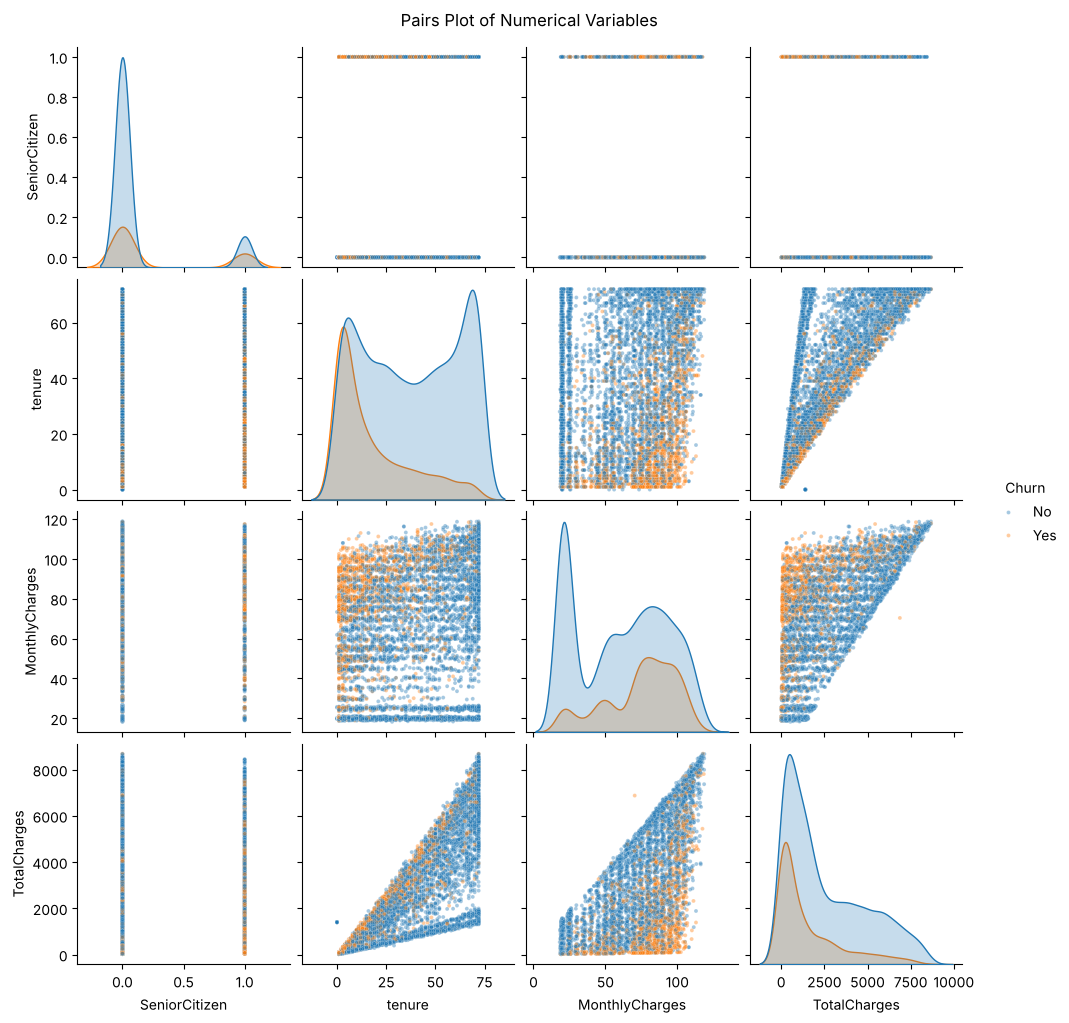

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.016547        0.220200      0.102652
tenure               0.016547  1.000000        0.247916      0.825433
MonthlyCharges       0.220200  0.247916        1.000000      0.650558
TotalCharges         0.102652  0.825433        0.650558      1.000000


In [79]:
#Pairs Plot - PDF #5 - Question #8
pair_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
sns.pairplot(df[pair_cols + ["Churn"]], hue="Churn", plot_kws={"s": 8, "alpha": 0.4})
plt.suptitle("Pairs Plot of Numerical Variables", y=1.02)
plt.show()
print(df[pair_cols].corr())

### Parallel Coordinate Plot - PDF #5 - Question #9

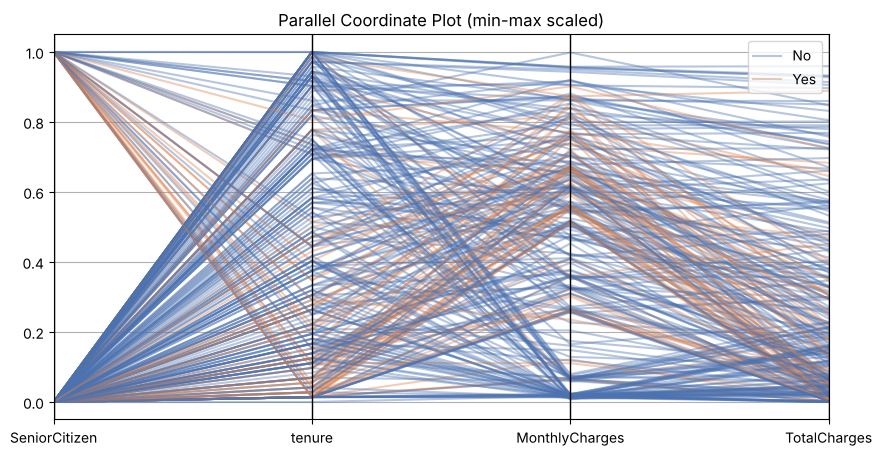

In [80]:
#Parallel Coordinate Plot - PDF #5 - Question #9
pc = df[pair_cols].apply(lambda x: (x - x.min()) / (x.max() - x.min()))
pc["Churn"] = df["Churn"]
plt.figure(figsize=(10, 5))
parallel_coordinates(pc.sample(300, random_state=1), "Churn", color=["#4C72B0", "#DD8452"], alpha=0.4)
plt.title("Parallel Coordinate Plot (min-max scaled)")
plt.show()

## PDF 6 - Time Series Analysis

### Load Dataset (series = avg MonthlyCharges by tenure month) - PDF #6 - Question #1

In [81]:
#Load Dataset (series = avg MonthlyCharges by tenure month) - PDF #6 - Question #1
df = load_clean()
s = df[df["tenure"] > 0].groupby("tenure")["MonthlyCharges"].mean()
ts = pd.Series(s.values, index=pd.period_range("2019-01", periods=len(s), freq="M"), name="AvgMonthlyCharges")

### First 5 and Last 5 Observations - PDF #6 - Question #2

In [82]:
#First 5 and Last 5 Observations - PDF #6 - Question #2
print(ts.head(5))
print(ts.tail(5))

2019-01    50.485808
2019-02    57.206303
2019-03    58.015000
2019-04    57.459943
2019-05    61.003759
Freq: M, Name: AvgMonthlyCharges, dtype: float64
2024-08    73.321000
2024-09    70.823158
2024-10    76.378992
2024-11    73.735588
2024-12    80.695856
Freq: M, Name: AvgMonthlyCharges, dtype: float64


### Start and End - PDF #6 - Question #3

In [83]:
#Start and End - PDF #6 - Question #3
print("Start:", ts.index[0], "End:", ts.index[-1])

Start: 2019-01 End: 2024-12


### Frequency and Class - PDF #6 - Question #4

In [84]:
#Frequency and Class - PDF #6 - Question #4
print("Frequency:", ts.index.freqstr, "(12 per year)")
print("Class:", type(ts), "| Length:", len(ts))

Frequency: M (12 per year)
Class: <class 'pandas.Series'> | Length: 72


### Plot Trend - PDF #6 - Question #5

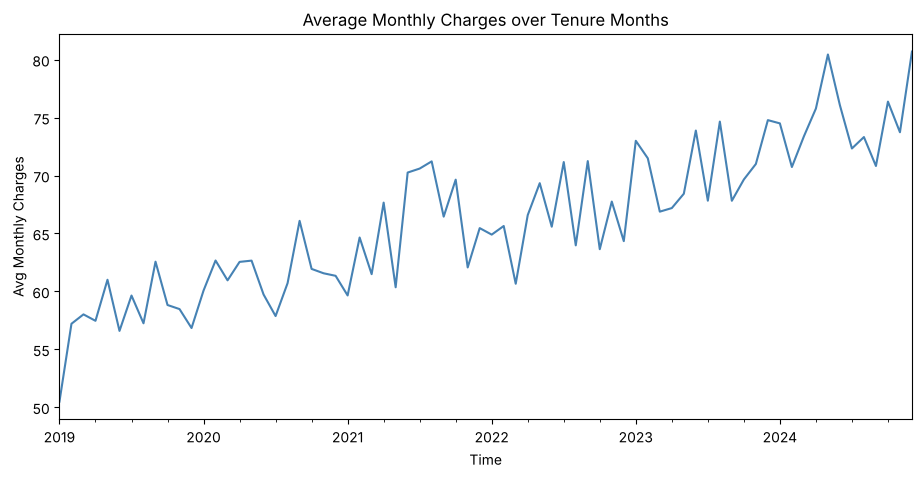

In [85]:
#Plot Trend - PDF #6 - Question #5
plt.figure(figsize=(11, 5))
ts.plot(color="steelblue")
plt.title("Average Monthly Charges over Tenure Months")
plt.xlabel("Time")
plt.ylabel("Avg Monthly Charges")
plt.show()

### Decompose - PDF #6 - Question #6

In [86]:
#Decompose - PDF #6 - Question #6
decomp = seasonal_decompose(ts.to_timestamp(), model="additive", period=12)
print(decomp.trend.dropna().head())
print(decomp.seasonal.head(12))

2019-07-01    58.261511
2019-08-01    58.888358
2019-09-01    59.238277
2019-10-01    59.572621
2019-11-01    59.853333
Freq: MS, Name: trend, dtype: float64
2019-01-01   -0.018933
2019-02-01    0.354226
2019-03-01   -2.212974
2019-04-01    0.852390
2019-05-01    0.871557
2019-06-01    1.403521
2019-07-01    0.719835
2019-08-01    0.547577
2019-09-01    1.579536
2019-10-01   -0.794108
2019-11-01   -1.680060
2019-12-01   -1.622567
Freq: MS, Name: seasonal, dtype: float64


### Plot Decomposed Components - PDF #6 - Question #7

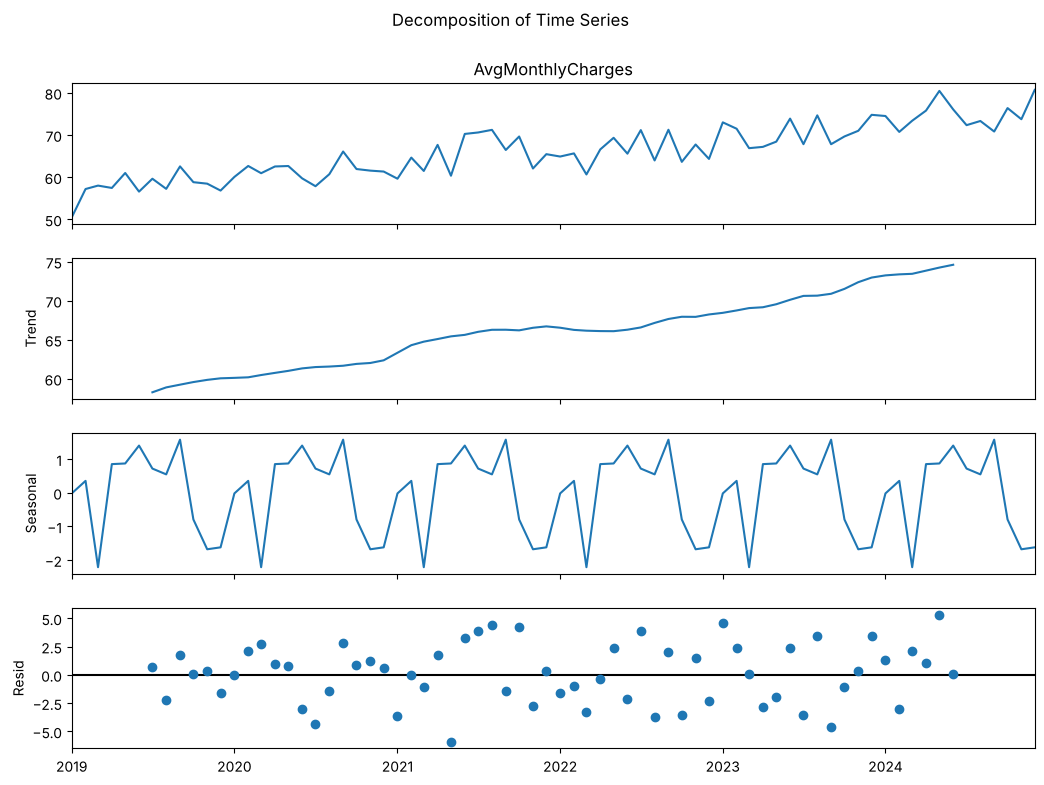

In [87]:
#Plot Decomposed Components - PDF #6 - Question #7
fig = decomp.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Decomposition of Time Series", y=1.01)
plt.show()

### ACF and PACF - PDF #6 - Question #8

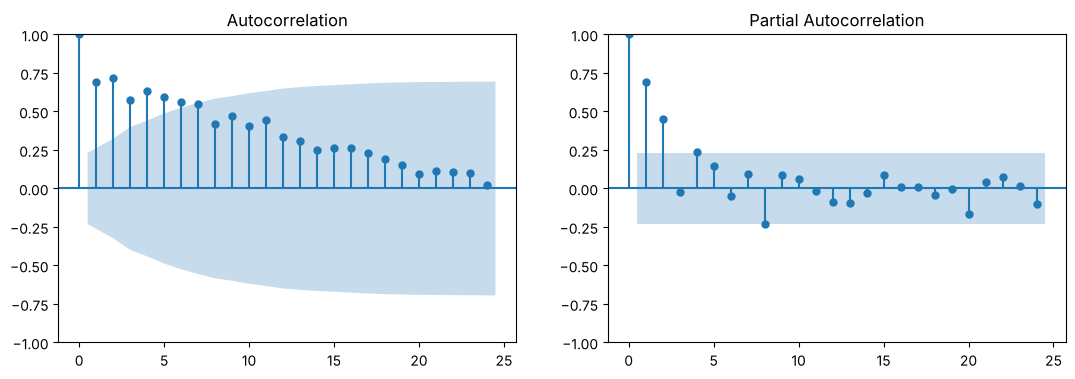

In [88]:
#ACF and PACF - PDF #6 - Question #8
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(ts.values, lags=24, ax=axes[0])
plot_pacf(ts.values, lags=24, ax=axes[1], method="ywm")
plt.show()

### Fit ARIMA - PDF #6 - Question #9

In [89]:
#Fit ARIMA - PDF #6 - Question #9
model = ARIMA(ts, order=(1, 1, 1)).fit()

### ARIMA Summary - PDF #6 - Question #10

In [90]:
#ARIMA Summary - PDF #6 - Question #10
print(model.summary())
print("AIC:", model.aic, "| BIC:", model.bic)

                               SARIMAX Results                                
Dep. Variable:      AvgMonthlyCharges   No. Observations:                   72
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -188.754
Date:                Fri, 16 Oct 2026   AIC                            383.507
Time:                        15:49:54   BIC                            390.295
Sample:                    01-31-2019   HQIC                           386.207
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1844      0.178     -1.036      0.300      -0.533       0.165
ma.L1         -0.5926      0.157     -3.774      0.000      -0.900      -0.285
sigma2        11.8178      2.540      4.654      0.0

### Forecast 12 Months - PDF #6 - Question #11

In [91]:
#Forecast 12 Months - PDF #6 - Question #11
fc = model.get_forecast(steps=12)
fc_mean = fc.predicted_mean
fc_ci = fc.conf_int()
print(pd.DataFrame({"Forecast": fc_mean, "Lower": fc_ci.iloc[:, 0], "Upper": fc_ci.iloc[:, 1]}))

          Forecast      Lower      Upper
2025-01  75.527524  68.789746  82.265301
2025-02  76.480380  69.577084  83.383676
2025-03  76.304707  68.973576  83.635839
2025-04  76.337095  68.656672  84.017518
2025-05  76.331124  68.307184  84.355065
2025-06  76.332225  67.980561  84.683888
2025-07  76.332022  67.664721  84.999323
2025-08  76.332059  67.360271  85.303848
2025-09  76.332053  67.065767  85.598338
2025-10  76.332054  66.780349  85.883759
2025-11  76.332054  66.503214  86.160894
2025-12  76.332054  66.233681  86.430426


### Plot Actual vs Forecast - PDF #6 - Question #12

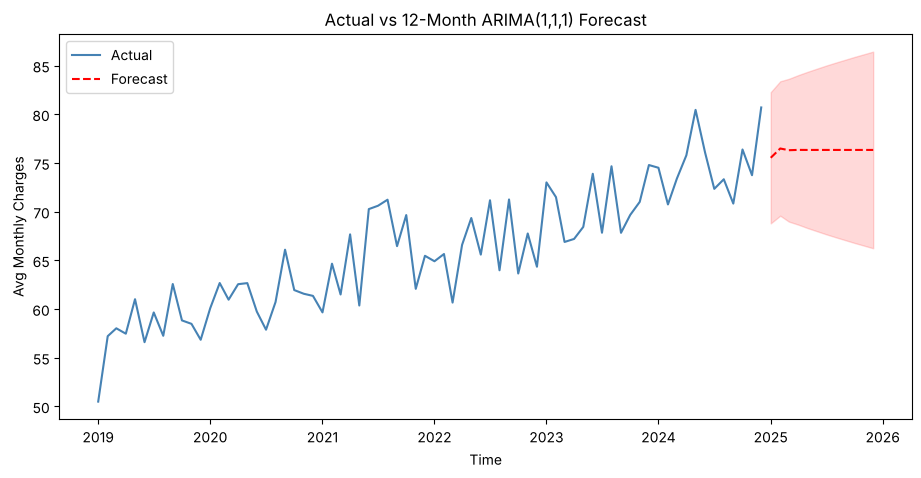

In [92]:
#Plot Actual vs Forecast - PDF #6 - Question #12
plt.figure(figsize=(11, 5))
plt.plot(ts.index.to_timestamp(), ts.values, label="Actual", color="steelblue")
plt.plot(fc_mean.index.to_timestamp(), fc_mean.values, label="Forecast", color="red", linestyle="--")
plt.fill_between(fc_mean.index.to_timestamp(), fc_ci.iloc[:, 0], fc_ci.iloc[:, 1], color="red", alpha=0.15)
plt.title("Actual vs 12-Month ARIMA(1,1,1) Forecast")
plt.xlabel("Time")
plt.ylabel("Avg Monthly Charges")
plt.legend()
plt.show()

## PDF 7 - 1D, 2D and ND Analysis

### Load Dataset - PDF #7 - Question #1

In [93]:
#Load Dataset - PDF #7 - Question #1
df = load_clean()

### Summary Statistics - PDF #7 - Question #2

In [94]:
#Summary Statistics - PDF #7 - Question #2
x = df["MonthlyCharges"]
mean, median, mn, mx = x.mean(), x.median(), x.min(), x.max()
rng, var, sd = mx - mn, x.var(), x.std()
iqr = x.quantile(0.75) - x.quantile(0.25)
skew, kurt = stats.skew(x), stats.kurtosis(x)

### Store in Structured Data Frame - PDF #7 - Question #3

In [95]:
#Store in Structured Data Frame - PDF #7 - Question #3
summary = pd.DataFrame({"Statistic": ["Mean", "Median", "Minimum", "Maximum", "Range", "Variance", "SD", "IQR", "Skewness", "Kurtosis"],
                        "Value": [mean, median, mn, mx, rng, var, sd, iqr, skew, kurt]}).round(4)
print(summary)

  Statistic     Value
0      Mean   64.7643
1    Median   70.3500
2   Minimum   18.2500
3   Maximum  118.7500
4     Range  100.5000
5  Variance  904.8783
6        SD   30.0812
7       IQR   54.3250
8  Skewness   -0.2209
9  Kurtosis   -1.2564


### Frequency & Relative Frequency + Pie + Bar - PDF #7 - Question #4

                Frequency  Relative Frequency
Contract                                     
Month-to-month       3875              0.5502
Two year             1695              0.2407
One year             1473              0.2091


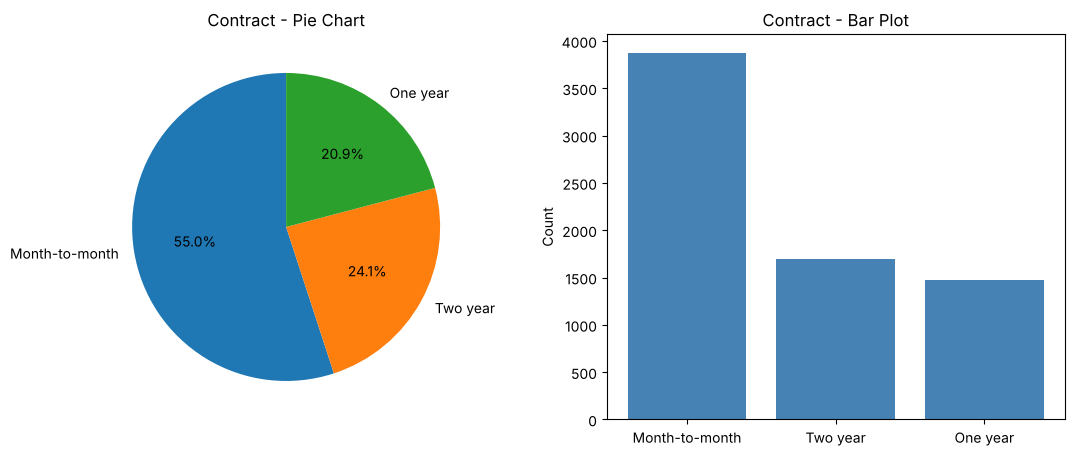

In [96]:
#Frequency & Relative Frequency + Pie + Bar - PDF #7 - Question #4
f = df["Contract"].value_counts()
print(pd.DataFrame({"Frequency": f, "Relative Frequency": (f / f.sum()).round(4)}))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie(f.values, labels=f.index, autopct="%1.1f%%", startangle=90)
axes[0].set_title("Contract - Pie Chart")
axes[1].bar(f.index, f.values, color="steelblue")
axes[1].set_title("Contract - Bar Plot")
axes[1].set_ylabel("Count")
plt.show()

### Binned Frequency Table + Histogram + Box Plot - PDF #7 - Question #5

tenure
(-0.001, 12.0]    2186
(12.0, 24.0]      1023
(24.0, 36.0]       833
(36.0, 48.0]       762
(48.0, 60.0]       832
(60.0, 72.0]      1407
Name: count, dtype: int64


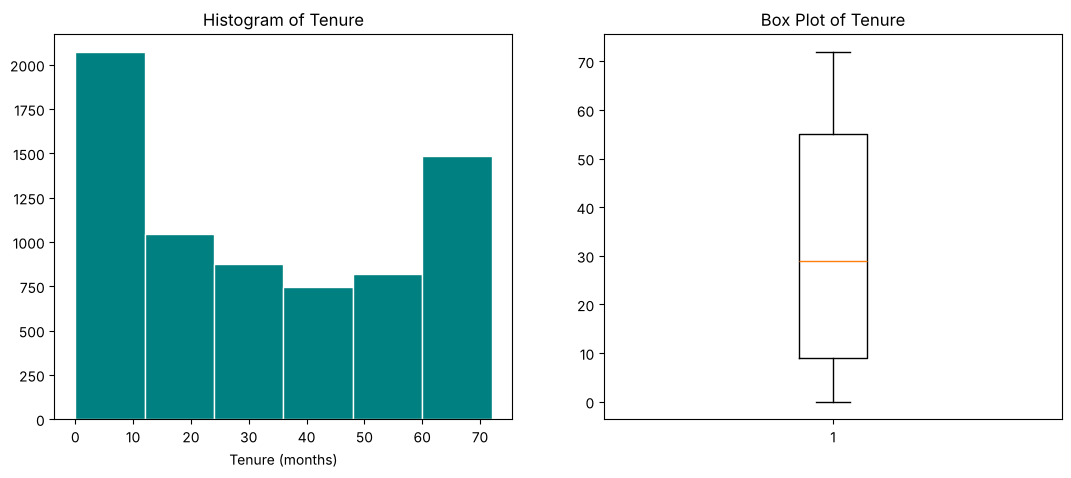

In [97]:
#Binned Frequency Table + Histogram + Box Plot - PDF #7 - Question #5
bins = pd.cut(df["tenure"], bins=[0, 12, 24, 36, 48, 60, 72], include_lowest=True)
print(bins.value_counts().sort_index())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(df["tenure"], bins=[0, 12, 24, 36, 48, 60, 72], color="teal", edgecolor="white")
axes[0].set_title("Histogram of Tenure")
axes[0].set_xlabel("Tenure (months)")
axes[1].boxplot(df["tenure"])
axes[1].set_title("Box Plot of Tenure")
plt.show()

### Contingency Table + Row/Column % - PDF #7 - Question #6

In [98]:
#Contingency Table + Row/Column % - PDF #7 - Question #6
ct = pd.crosstab(df["InternetService"], df["Churn"])
print(ct)
print((ct.div(ct.sum(axis=1), axis=0) * 100).round(2))
print((ct.div(ct.sum(axis=0), axis=1) * 100).round(2))

Churn              No   Yes
InternetService            
DSL              1963   458
Fiber optic      1799  1297
No               1413   113
Churn               No    Yes
InternetService              
DSL              81.08  18.92
Fiber optic      58.11  41.89
No               92.60   7.40
Churn               No    Yes
InternetService              
DSL              37.93  24.52
Fiber optic      34.76  69.43
No               27.30   6.05


### Stacked Bar Plot - PDF #7 - Question #7

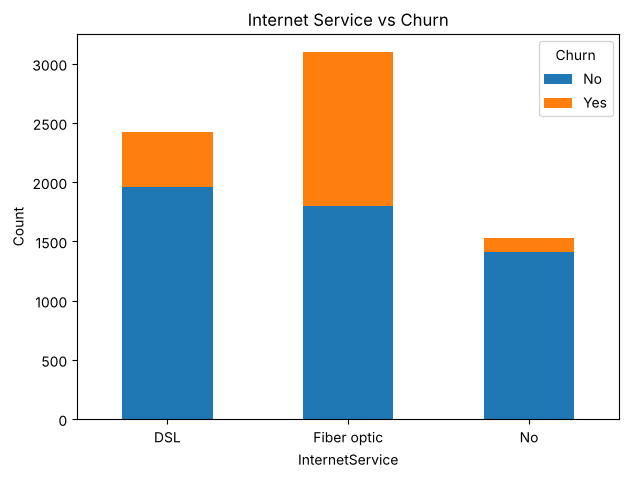

In [99]:
#Stacked Bar Plot - PDF #7 - Question #7
ct.plot(kind="bar", stacked=True, figsize=(7, 5))
plt.title("Internet Service vs Churn")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

### Grouped Mean, Median, SD (aggregate) - PDF #7 - Question #8

In [100]:
#Grouped Mean, Median, SD (aggregate) - PDF #7 - Question #8
print(df.groupby("Contract")["MonthlyCharges"].agg(["mean", "median", "std"]).round(3))

                  mean  median     std
Contract                              
Month-to-month  66.400   73.25  26.927
One year        65.023   68.75  31.822
Two year        60.800   64.35  34.665


### Side-by-Side Box + Violin - PDF #7 - Question #9

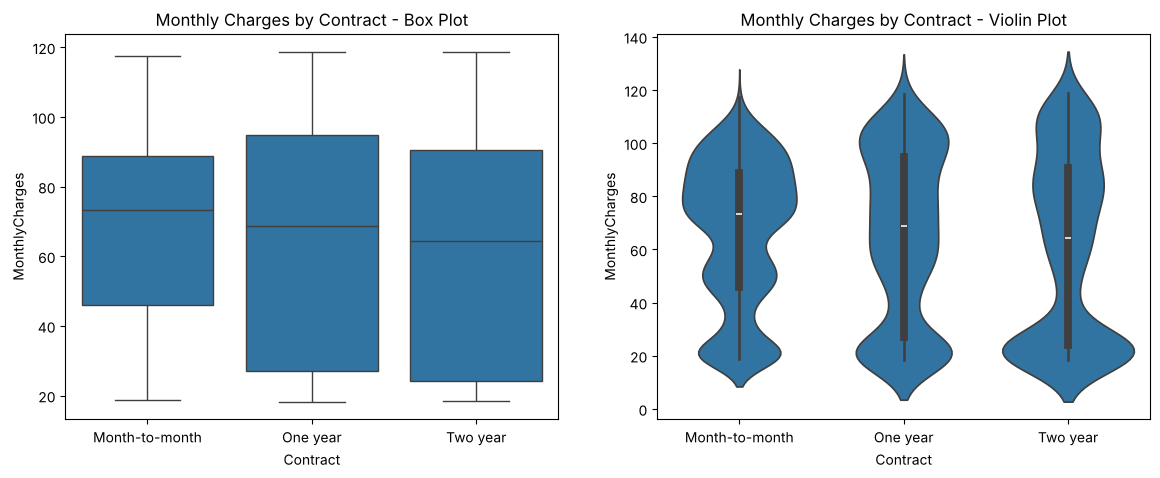

In [101]:
#Side-by-Side Box + Violin - PDF #7 - Question #9
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Contract", y="MonthlyCharges", ax=axes[0])
axes[0].set_title("Monthly Charges by Contract - Box Plot")
sns.violinplot(data=df, x="Contract", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Contract - Violin Plot")
plt.show()

### Pearson & Spearman + Scatter with Trend Line - PDF #7 - Question #10

Pearson: 0.8254330756776308
Spearman: 0.8869421800059288


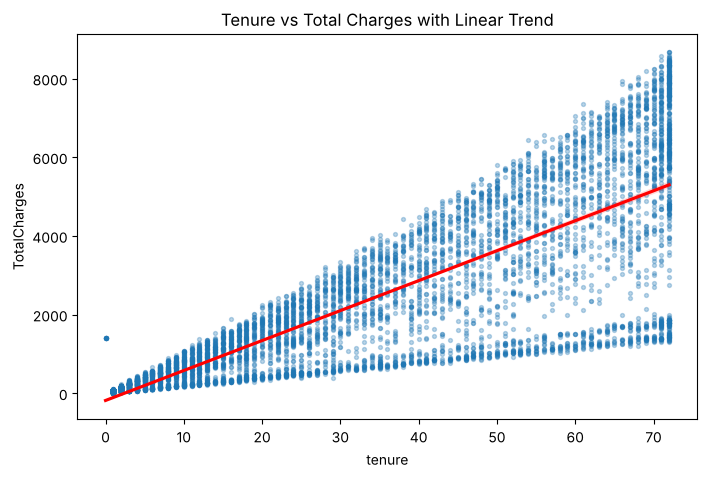

                        mean     std
Contract       Churn                
Month-to-month No     61.458  27.860
               Yes    73.036  24.082
One year       No     62.508  31.659
               Yes    84.827  25.606
Two year       No     60.043  34.534
               Yes    86.777  28.918


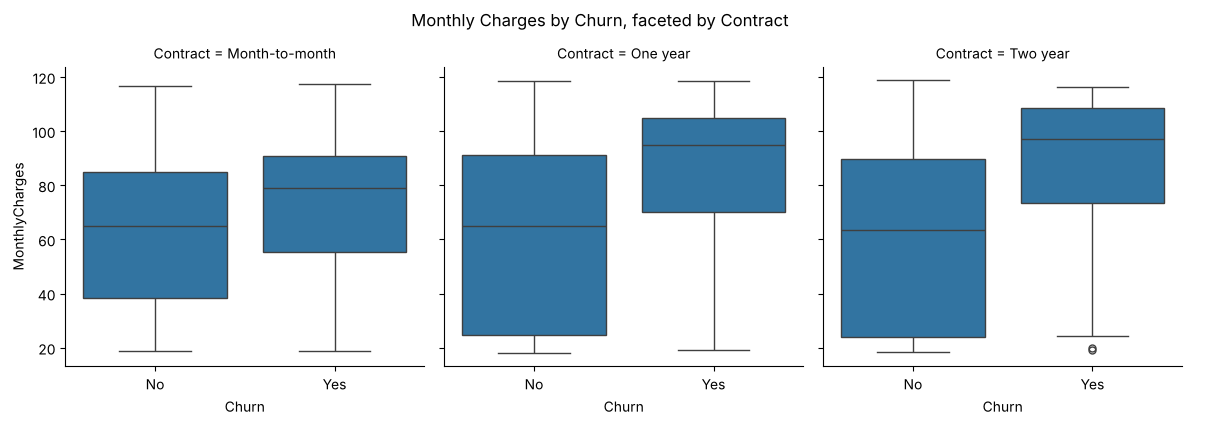

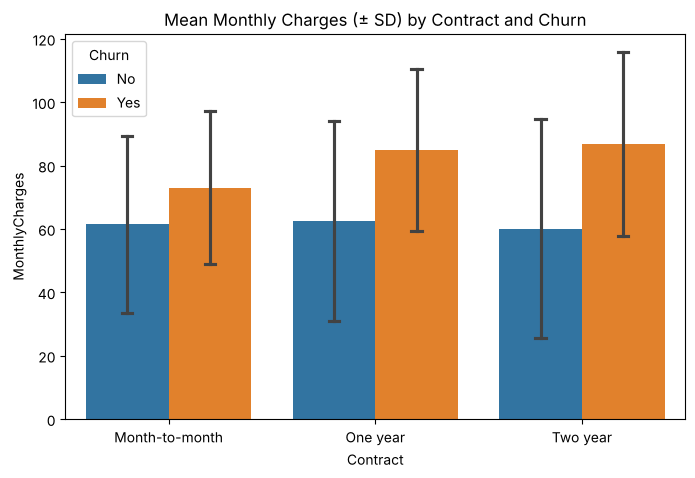

In [102]:
#Pearson & Spearman + Scatter with Trend Line - PDF #7 - Question #10
print("Pearson:", df["tenure"].corr(df["TotalCharges"], method="pearson"))
print("Spearman:", df["tenure"].corr(df["TotalCharges"], method="spearman"))
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="tenure", y="TotalCharges", scatter_kws={"s": 8, "alpha": 0.3}, line_kws={"color": "red"})
plt.title("Tenure vs Total Charges with Linear Trend")
plt.show()

#2 Categorical + 1 Numerical Stats, Faceted Box, Grouped Bar w/ Error Bars - PDF #7 - Question #11
print(df.groupby(["Contract", "Churn"])["MonthlyCharges"].agg(["mean", "std"]).round(3))
g = sns.catplot(data=df, x="Churn", y="MonthlyCharges", col="Contract", kind="box", height=4)
g.figure.suptitle("Monthly Charges by Churn, faceted by Contract", y=1.05)
plt.show()
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Contract", y="MonthlyCharges", hue="Churn", errorbar="sd", capsize=0.1)
plt.title("Mean Monthly Charges (± SD) by Contract and Churn")
plt.show()

### Scatter Colored/Shaped by Category + Per-Category Correlation - PDF #7 - Question #12

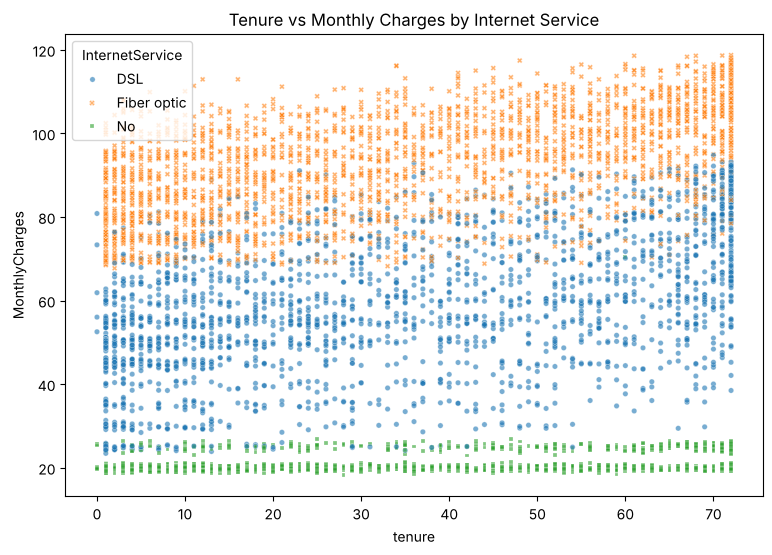

DSL
                  tenure  MonthlyCharges
tenure          1.000000        0.517156
MonthlyCharges  0.517156        1.000000
Fiber optic
                  tenure  MonthlyCharges
tenure          1.000000        0.623333
MonthlyCharges  0.623333        1.000000
No
                  tenure  MonthlyCharges
tenure          1.000000        0.312432
MonthlyCharges  0.312432        1.000000


In [103]:
#Scatter Colored/Shaped by Category + Per-Category Correlation - PDF #7 - Question #12
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="InternetService", style="InternetService", s=15, alpha=0.6)
plt.title("Tenure vs Monthly Charges by Internet Service")
plt.show()
for grp, sub in df.groupby("InternetService"):
    print(grp)
    print(sub[["tenure", "MonthlyCharges"]].corr())

### Correlation Matrix Heatmap (>=3 numeric) - PDF #7 - Question #13

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.016547        0.220200      0.102652
tenure               0.016547  1.000000        0.247916      0.825433
MonthlyCharges       0.220200  0.247916        1.000000      0.650558
TotalCharges         0.102652  0.825433        0.650558      1.000000


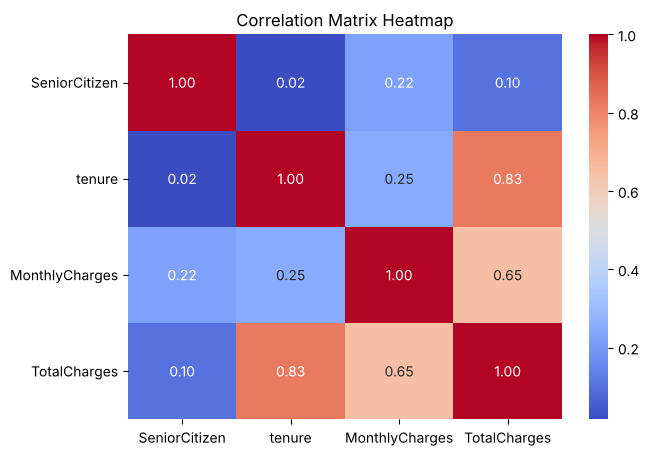

In [104]:
#Correlation Matrix Heatmap (>=3 numeric) - PDF #7 - Question #13
cm = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].corr()
print(cm)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

### Pairs Plot / Scatterplot Matrix - PDF #7 - Question #14

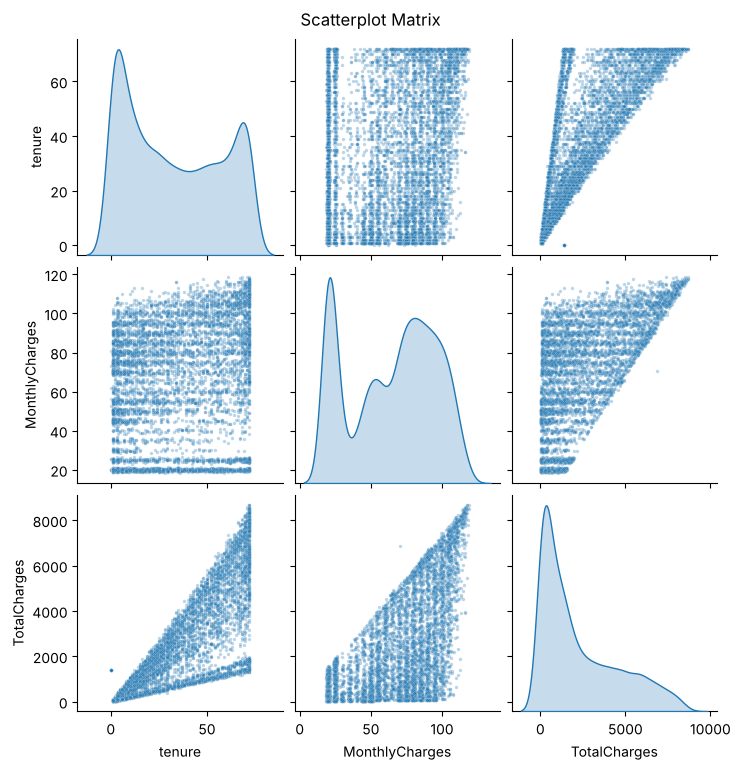

In [105]:
#Pairs Plot / Scatterplot Matrix - PDF #7 - Question #14
sns.pairplot(df[["tenure", "MonthlyCharges", "TotalCharges"]], diag_kind="kde", plot_kws={"s": 6, "alpha": 0.3})
plt.suptitle("Scatterplot Matrix", y=1.02)
plt.show()

## PDF 8 - K-Means Clustering

### Load Dataset - PDF #8 - K-Means - Question #1

In [106]:
#Load Dataset - PDF #8 - K-Means - Question #1
df = load_raw()

### View Dataset - PDF #8 - K-Means - Question #2

In [107]:
#View Dataset - PDF #8 - K-Means - Question #2
print(df.head())
df.info()

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines  \
0  7590-VHVEG  Female            0.0     Yes         No     1.0           No  No phone service   
1  5575-GNVDE    Male            0.0      No         No    34.0          Yes                No   
2  3668-QPYBK    Male            0.0      No         No     2.0          Yes                No   
3  7795-CFOCW    Male            0.0      No         No    45.0           No  No phone service   
4  9237-HQITU  Female            0.0      No         No     2.0          Yes                No   

  InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies  \
0             DSL             No          Yes               No          No          No              No   
1             DSL            Yes           No              Yes          No          No              No   
2             DSL            Yes          Yes               No          No          No       

### Check Missing Values - PDF #8 - K-Means - Question #3

In [108]:
#Check Missing Values - PDF #8 - K-Means - Question #3
print(df.isna().sum())

customerID           0
gender               0
SeniorCitizen        8
Partner              5
Dependents           2
tenure               2
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          1
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     1
PaymentMethod        0
MonthlyCharges       3
TotalCharges        11
Churn                3
dtype: int64


### Dependent Variable Distribution (table) - PDF #8 - K-Means - Question #4

In [109]:
#Dependent Variable Distribution (table) - PDF #8 - K-Means - Question #4
print(df["Churn"].value_counts(dropna=False))

Churn
No     5172
Yes    1868
NaN       3
Name: count, dtype: int64


### Select Numerical Features - PDF #8 - K-Means - Question #5

In [110]:
#Select Numerical Features - PDF #8 - K-Means - Question #5
km_data = df.select_dtypes(include="number").dropna()
print(km_data.head())

   SeniorCitizen  tenure  MonthlyCharges  TotalCharges
0            0.0     1.0           29.85         29.85
1            0.0    34.0           56.95       1889.50
2            0.0     2.0           53.85        108.15
3            0.0    45.0           42.30       1840.75
4            0.0     2.0           70.70        151.65


### Standardize (scale) - PDF #8 - K-Means - Question #6

In [111]:
#Standardize (scale) - PDF #8 - K-Means - Question #6
km_scaled = r_scale(km_data)
print(km_scaled.head())

   SeniorCitizen    tenure  MonthlyCharges  TotalCharges
0      -0.440782 -1.279515       -1.162064     -0.994168
1      -0.440782  0.064720       -0.261030     -0.173506
2      -0.440782 -1.238781       -0.364101     -0.959614
3      -0.440782  0.512799       -0.748120     -0.195019
4      -0.440782 -1.238781        0.196136     -0.940418


### K-Means with k=2 - PDF #8 - K-Means - Question #7

In [112]:
#K-Means with k=2 - PDF #8 - K-Means - Question #7
km2 = KMeans(n_clusters=2, n_init=25, random_state=42).fit(km_scaled)

### Display K-Means Results - PDF #8 - K-Means - Question #8

In [113]:
#Display K-Means Results - PDF #8 - K-Means - Question #8
print("Cluster sizes:", np.bincount(km2.labels_))
print("Cluster labels (first 20):", km2.labels_[:20])
tss = ((km_scaled - km_scaled.mean()) ** 2).sum().sum()
print("Total WCSS:", km2.inertia_, "| Between_SS / Total_SS =", round((tss - km2.inertia_) / tss * 100, 2), "%")

Cluster sizes: [4620 2399]
Cluster labels (first 20): [0 0 0 0 0 0 0 0 1 1 0 0 1 1 1 1 1 0 0 0]
Total WCSS: 16591.939219150347 | Between_SS / Total_SS = 40.9 %


### Cluster Centers - PDF #8 - K-Means - Question #9

In [114]:
#Cluster Centers - PDF #8 - K-Means - Question #9
print(pd.DataFrame(km2.cluster_centers_, columns=km_data.columns))

   SeniorCitizen    tenure  MonthlyCharges  TotalCharges
0      -0.112845 -0.506470       -0.428978     -0.630153
1       0.217042  0.974127        0.825081      1.212015


### WCSS for K = 1 to 10 - PDF #8 - K-Means - Question #10

In [115]:
#WCSS for K = 1 to 10 - PDF #8 - K-Means - Question #10
wcss = [KMeans(n_clusters=k, n_init=25, random_state=42).fit(km_scaled).inertia_ for k in range(1, 11)]
print(pd.DataFrame({"K": range(1, 11), "WCSS": wcss}))

    K          WCSS
0   1  28072.000000
1   2  16591.939219
2   3  11212.859426
3   4   8265.424751
4   5   6456.925166
5   6   4666.217315
6   7   3833.652692
7   8   3393.496517
8   9   3020.576773
9  10   2677.997871


### Elbow Plot - PDF #8 - K-Means - Question #11

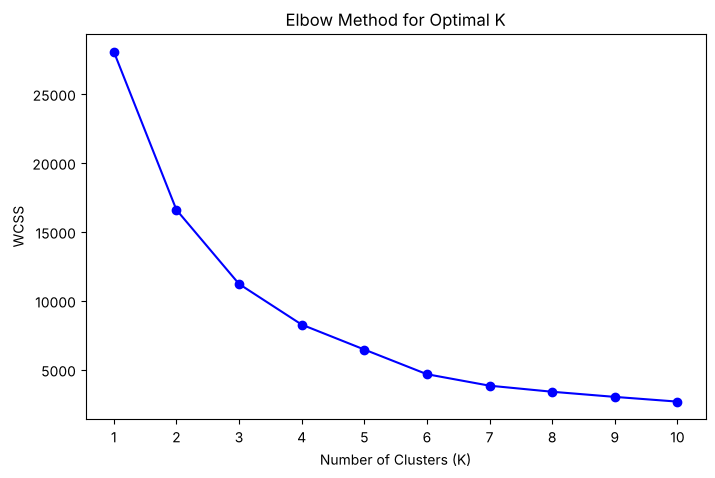

In [116]:
#Elbow Plot - PDF #8 - K-Means - Question #11
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, "bo-")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.show()

### K-Means with Elbow-Recommended K - PDF #8 - K-Means - Question #12

In [117]:
#K-Means with Elbow-Recommended K - PDF #8 - K-Means - Question #12
kx = (np.arange(1, 11) - 1) / 9
wy = (np.array(wcss) - min(wcss)) / (max(wcss) - min(wcss))
best_k = int(np.argmax(1 - kx - wy) + 1)
print("Elbow K:", best_k)
km_best = KMeans(n_clusters=best_k, n_init=25, random_state=42).fit(km_scaled)
print("Cluster sizes:", np.bincount(km_best.labels_))
print(pd.DataFrame(km_best.cluster_centers_, columns=km_data.columns))

Elbow K: 4


Cluster sizes: [1957 1746 1142 2174]
   SeniorCitizen    tenure  MonthlyCharges  TotalCharges
0      -0.440782 -0.114266       -1.302056     -0.659434
1      -0.440782  1.079717        0.793447      1.294881
2       2.268370  0.036042        0.499374      0.232915
3      -0.440782 -0.781511        0.273009     -0.566979


### Load Dataset - PDF #8 - Hierarchical - Question #1

In [118]:
#Load Dataset - PDF #8 - Hierarchical - Question #1
df = load_raw()

### View Dataset - PDF #8 - Hierarchical - Question #2

In [119]:
#View Dataset - PDF #8 - Hierarchical - Question #2
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines  \
0  7590-VHVEG  Female            0.0     Yes         No     1.0           No  No phone service   
1  5575-GNVDE    Male            0.0      No         No    34.0          Yes                No   
2  3668-QPYBK    Male            0.0      No         No     2.0          Yes                No   
3  7795-CFOCW    Male            0.0      No         No    45.0           No  No phone service   
4  9237-HQITU  Female            0.0      No         No     2.0          Yes                No   

  InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies  \
0             DSL             No          Yes               No          No          No              No   
1             DSL            Yes           No              Yes          No          No              No   
2             DSL            Yes          Yes               No          No          No       

### Check Missing Values - PDF #8 - Hierarchical - Question #3

In [120]:
#Check Missing Values - PDF #8 - Hierarchical - Question #3
print(df.isna().sum())

customerID           0
gender               0
SeniorCitizen        8
Partner              5
Dependents           2
tenure               2
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          1
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     1
PaymentMethod        0
MonthlyCharges       3
TotalCharges        11
Churn                3
dtype: int64


### Select Numerical Attributes - PDF #8 - Hierarchical - Question #4

In [121]:
#Select Numerical Attributes - PDF #8 - Hierarchical - Question #4
hc_data = df.select_dtypes(include="number").dropna()

### Standardize (scale) - PDF #8 - Hierarchical - Question #5

In [122]:
#Standardize (scale) - PDF #8 - Hierarchical - Question #5
hc_scaled = r_scale(hc_data)

### Euclidean Distance (dist) - PDF #8 - Hierarchical - Question #6

In [123]:
#Euclidean Distance (dist) - PDF #8 - Hierarchical - Question #6
d = pdist(hc_scaled.values, metric="euclidean")
print("Number of pairwise distances:", len(d))

Number of pairwise distances: 24629671


### Ward's Method (hclust) - PDF #8 - Hierarchical - Question #7

In [124]:
#Ward's Method (hclust) - PDF #8 - Hierarchical - Question #7
hc = linkage(d, method="ward")

### Dendrogram - PDF #8 - Hierarchical - Question #8

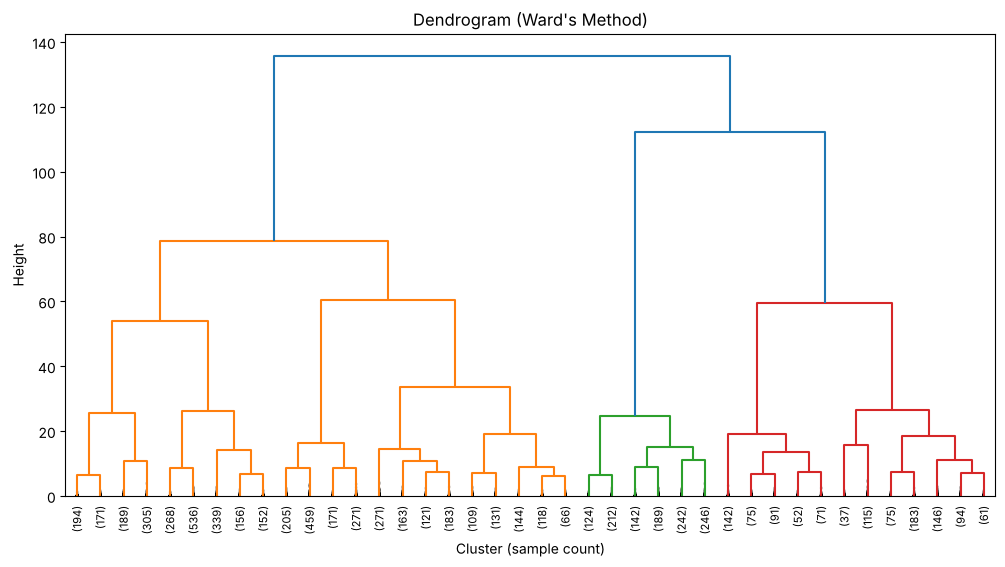

[1 1 1 1 1 1 1 1 1 1 1 1 2 2 1 2 2 1 1 3 1 1 1 1 1 2 1 2 1 3]


In [125]:
#Dendrogram - PDF #8 - Hierarchical - Question #8
plt.figure(figsize=(12, 6))
dendrogram(hc, truncate_mode="lastp", p=40, leaf_rotation=90, show_contracted=True)
plt.title("Dendrogram (Ward's Method)")
plt.xlabel("Cluster (sample count)")
plt.ylabel("Height")
plt.show()

#3 Clusters + Assignments (cutree) - PDF #8 - Hierarchical - Question #9
clusters = fcluster(hc, t=3, criterion="maxclust")
print(clusters[:30])

### Samples per Cluster (table) - PDF #8 - Hierarchical - Question #10

In [126]:
#Samples per Cluster (table) - PDF #8 - Hierarchical - Question #10
print(pd.Series(clusters).value_counts().sort_index())

1    4722
2    1155
3    1142
Name: count, dtype: int64


## PDF 9 - Principal Component Analysis

### Load Dataset + Verify Packages - PDF #9 - Question #1

In [127]:
#Load Dataset + Verify Packages - PDF #9 - Question #1
df = load_raw()
import sklearn, matplotlib, statsmodels
print("pandas", pd.__version__, "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", sns.__version__, "| statsmodels", statsmodels.__version__)

pandas 3.0.5 | sklearn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2 | statsmodels 0.15.0


### Rows and Columns - PDF #9 - Question #2

In [128]:
#Rows and Columns - PDF #9 - Question #2
print("Rows:", df.shape[0], "Columns:", df.shape[1])

Rows: 7043 Columns: 21


### Numeric Columns, Clean, Scale -> data_scaled - PDF #9 - Question #3

In [129]:
#Numeric Columns, Clean, Scale -> data_scaled - PDF #9 - Question #3
num = df.select_dtypes(include="number").dropna().drop_duplicates()
data_scaled = r_scale(num)
print(data_scaled.head())

   SeniorCitizen    tenure  MonthlyCharges  TotalCharges
0      -0.447299 -1.335373       -1.196198     -1.026105
1      -0.447299  0.023973       -0.290238     -0.205285
2      -0.447299 -1.294181       -0.393872     -0.991544
3      -0.447299  0.477088       -0.779991     -0.226803
4      -0.447299 -1.294181        0.169428     -0.972344


### PCA + Summary - PDF #9 - Question #4

In [130]:
#PCA + Summary - PDF #9 - Question #4
pca = PCA().fit(data_scaled)
pcs = [f"PC{i+1}" for i in range(pca.n_components_)]
print(pd.DataFrame({"Standard deviation": np.sqrt(pca.explained_variance_),
                    "Proportion of Variance": pca.explained_variance_ratio_,
                    "Cumulative Proportion": np.cumsum(pca.explained_variance_ratio_)}, index=pcs).T.round(4))
print(pd.DataFrame(pca.components_.T, index=num.columns, columns=pcs).round(4))

                           PC1     PC2     PC3     PC4
Standard deviation      1.4774  1.0336  0.8323  0.2372
Proportion of Variance  0.5457  0.2671  0.1732  0.0141
Cumulative Proportion   0.5457  0.8128  0.9859  1.0000
                   PC1     PC2     PC3     PC4
SeniorCitizen   0.1420  0.8594 -0.4910  0.0138
tenure          0.5503 -0.3698 -0.5036 -0.5539
MonthlyCharges  0.4903  0.3312  0.7108 -0.3803
TotalCharges    0.6608 -0.1225 -0.0025  0.7405


### Scree Plot (labels, ylim 0-60) - PDF #9 - Question #5

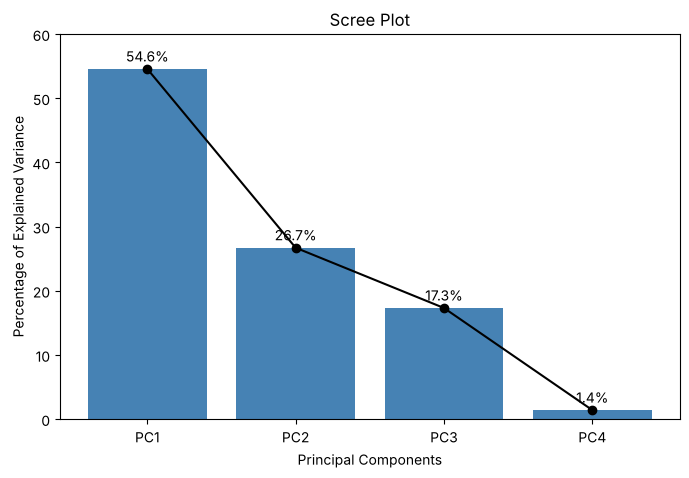

In [131]:
#Scree Plot (labels, ylim 0-60) - PDF #9 - Question #5
var_pct = pca.explained_variance_ratio_ * 100
plt.figure(figsize=(8, 5))
bars = plt.bar(pcs, var_pct, color="steelblue")
plt.plot(pcs, var_pct, "ko-")
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.ylim(0, 60)
plt.title("Scree Plot")
plt.xlabel("Principal Components")
plt.ylabel("Percentage of Explained Variance")
plt.show()

### PCA Biplot (non-overlapping labels) - PDF #9 - Question #6

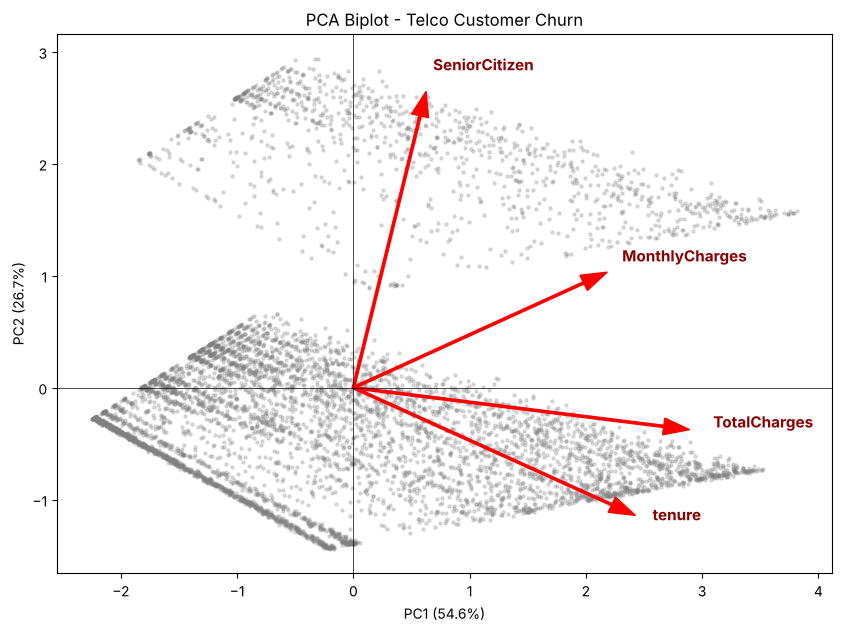

In [132]:
#PCA Biplot (non-overlapping labels) - PDF #9 - Question #6
scores = pca.transform(data_scaled)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
scale = np.abs(scores[:, :2]).max() / np.abs(loadings[:, :2]).max() * 0.7
plt.figure(figsize=(10, 7))
plt.scatter(scores[:, 0], scores[:, 1], s=5, alpha=0.25, color="grey")
texts = []
for i, var in enumerate(num.columns):
    plt.arrow(0, 0, loadings[i, 0] * scale, loadings[i, 1] * scale, color="red", width=0.02, head_width=0.15)
    texts.append(plt.text(loadings[i, 0] * scale * 1.15, loadings[i, 1] * scale * 1.15, var, color="darkred", fontsize=11, weight="bold"))
try:
    from adjustText import adjust_text
    adjust_text(texts, arrowprops=dict(arrowstyle="-", color="darkred"))
except ImportError:
    pass
plt.axhline(0, color="black", lw=0.5)
plt.axvline(0, color="black", lw=0.5)
plt.title("PCA Biplot - Telco Customer Churn")
plt.xlabel(f"PC1 ({var_pct[0]:.1f}%)")
plt.ylabel(f"PC2 ({var_pct[1]:.1f}%)")
plt.show()

### PCA Scores Data Frame (first 6) - PDF #9 - Question #7

In [133]:
#PCA Scores Data Frame (first 6) - PDF #9 - Question #7
pca_scores = pd.DataFrame(scores, columns=pcs, index=num.index)
print(pca_scores.head(6))

        PC1       PC2       PC3       PC4
0 -2.062872 -0.161041  0.044395  0.428640
1 -0.328290 -0.464248  0.001748 -0.061055
2 -1.624000  0.085203  0.593885  0.126260
3 -0.333289 -0.791373 -0.574529 -0.141698
4 -1.335136  0.269401  0.994250 -0.073767
5 -0.529555  0.462354  1.556995 -0.360149


### PC1 vs PC2 Scatter (blue circles, reg no.) - PDF #9 - Question #8

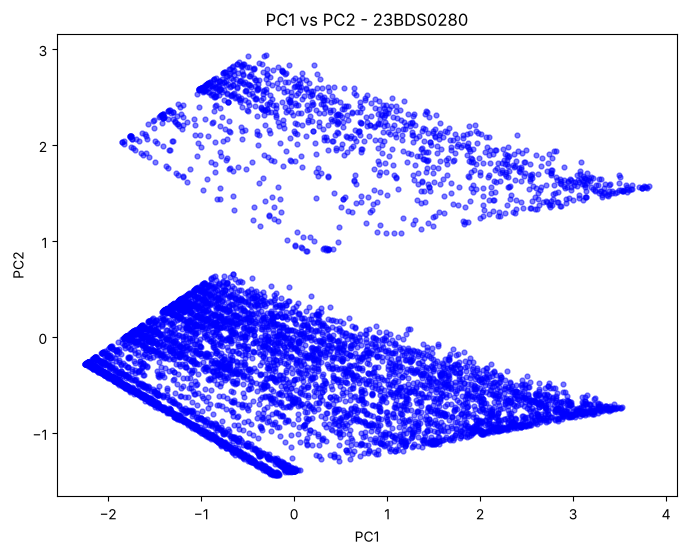

In [134]:
#PC1 vs PC2 Scatter (blue circles, reg no.) - PDF #9 - Question #8
plt.figure(figsize=(8, 6))
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", s=12, alpha=0.5)
plt.title(f"PC1 vs PC2 - {REG_NO}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()